# 12. Observability augmentation ablation

This notebook measures how much each augmentation changes the **dimensionless soft-projector observability target** itself.

For selected KAIST windows, it compares the cached/raw target \(o_{\mathrm{raw}}\) with a freshly recomputed target \(o_{\mathrm{aug}}\) after applying **one augmentation at a time**.

Primary diagnostics:
- Pearson correlation;
- identity \(R^2\), which penalizes bias and rescaling;
- MAE/RMSE of target drift;
- normalized RMSE \(=\mathrm{RMSE}(o_{\mathrm{aug}}-o_{\mathrm{raw}})/\mathrm{std}(o_{\mathrm{raw}})\);
- raw-vs-augmented scatter plots.

Default experiment: 48 evenly spaced `Urban16` windows, 5 stochastic draws per augmentation. Calibration events are intentionally excluded from the main comparison because they change the problem from one static calibration per window to a time-varying calibration.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import inspect
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, SE3NoiseConfig, VectorNoiseConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.config import WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.structures import MeasurementType
from obscalib.observability.estimators import ObservabilityMatrixEstimator
from obscalib.observability.layout import CalibrationParameterLayout
from obscalib.observability.mappings import dimensionless_soft_projector_observability
from obscalib.observability.numerics import ObservabilityNumericsConfig
from obscalib.observability.structures import ObservabilityResult

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [2]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
ABLATION_SEQUENCE_NAME = "Urban16"

NUM_ABLATION_WINDOWS = 64
NUM_AUGMENTATION_DRAWS = 5
ABLATION_RANDOM_SEED = 67890

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

CALIBRATION_KEYS = ("imu", "lidar")
CALIBRATION_COMPONENT_NAMES = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
INFORMATIVE_COMPONENTS = ("phi_x", "phi_y", "phi_z", "tau")

DIMENSIONLESS_ROTATION_SCALE_RAD = np.deg2rad(5.0)
DIMENSIONLESS_TRANSLATION_SCALE_M = 0.05
DIMENSIONLESS_TIME_OFFSET_SCALE_S = 0.015
DIMENSIONLESS_CALIBRATION_SCALE = (
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_ROTATION_SCALE_RAD,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TRANSLATION_SCALE_M,
    DIMENSIONLESS_TIME_OFFSET_SCALE_S,
)

LAMBDA_VALUE_SETTING = 0.25
USE_NJIT_OBSERVABILITY = True
PROJECTION_NUMERICAL_TOLERANCE = 1e-10
REFERENCE_LIDAR_STREAM_KEY = "lidar"

ABLATION_CACHE_VERSION = 1
FORCE_RECOMPUTE = False
ABLATION_OUTPUT_DIR = ROOT / "tmp" / "observability_augmentation_ablation"
ABLATION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = ABLATION_OUTPUT_DIR / f"v{ABLATION_CACHE_VERSION}_{ABLATION_SEQUENCE_NAME}_{NUM_ABLATION_WINDOWS}windows_{NUM_AUGMENTATION_DRAWS}draws.csv"

print("Sequence:", ABLATION_SEQUENCE_NAME)
print("Results cache:", RESULTS_PATH)


Sequence: Urban16
Results cache: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/tmp/observability_augmentation_ablation/v1_Urban16_64windows_5draws.csv


## 3. Load train dataset and choose representative windows


In [3]:
T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

train_specs = build_kaist_sequence_specs(sequence_names=TRAIN_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT)
train_dataset = KAISTCalibrationDataset(train_specs, rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

sequence_dataset_indices = np.asarray([i for i in range(len(train_dataset)) if train_dataset.sequence_name_for_window(i) == ABLATION_SEQUENCE_NAME], dtype=int)
if sequence_dataset_indices.size == 0:
    raise ValueError(f"No windows found for sequence {ABLATION_SEQUENCE_NAME!r}.")

num_selected = min(NUM_ABLATION_WINDOWS, sequence_dataset_indices.size)
selection_positions = np.linspace(0, sequence_dataset_indices.size - 1, num_selected).round().astype(int)
selected_dataset_indices = sequence_dataset_indices[selection_positions]

print(train_dataset.summary())
print()
print(f"Selected {len(selected_dataset_indices)} / {len(sequence_dataset_indices)} windows from {ABLATION_SEQUENCE_NAME}.")
print(selected_dataset_indices)


KAISTCalibrationDataset: 2005 windows from 6 sequences
approximate tensor storage: 37.4 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011
  Urban16: windows=780, duration=4458.2s, IMU=449215, LiDAR=37703

Selected 64 / 780 windows from Urban16.
[1225 1237 1250 1262 1274 1287 1299 1312 1324 1336 1349 1361 1373 1386
 1398 1410 1423 1435 1448 1460 1472 1485 1497 1509 1522 1534 1546 1559
 1571 1584 1596 1608 1621 1633 1645 1658 1670 1683 1695 1707 1720 1732
 1744 1757 1769 1781 1794 1806 1819 1831 1843 1856 1868 1880 1893 1905
 1917 1930 1942 1955 1967 1979 1992 2004]


## 4. Observability estimator


In [4]:
calibration_layout = CalibrationParameterLayout.from_calibration_keys(CALIBRATION_KEYS)

GYRO_MEASUREMENT_COVARIANCE = torch.tensor([
    [2.96367932e-06, -1.94438078e-07, -4.83643437e-07],
    [-1.94438078e-07, 1.89162212e-06, 1.09062693e-07],
    [-4.83643437e-07, 1.09062693e-07, 1.88843506e-06],
], dtype=torch.float64)

ACCEL_MEASUREMENT_COVARIANCE = torch.tensor([
    [4.85003041e-03, -9.25262862e-05, 2.14219676e-04],
    [-9.25262862e-05, 1.51980006e-03, -1.13182999e-03],
    [2.14219676e-04, -1.13182999e-03, 2.29777687e-03],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE = torch.tensor([
    [1.10442767e-05, 9.46809587e-07, 3.78536515e-06],
    [9.46809587e-07, 3.35041997e-05, 1.90008728e-06],
    [3.78536515e-06, 1.90008728e-06, 1.10553483e-05],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE = torch.tensor([
    [0.00843466, 0.00266052, 0.00702046],
    [0.00266052, 0.01444850, 0.00225705],
    [0.00702046, 0.00225705, 0.00704268],
], dtype=torch.float64)

LIDAR_SCAN_TO_MAP_COVARIANCE = torch.zeros((6, 6), dtype=torch.float64)
LIDAR_SCAN_TO_MAP_COVARIANCE[:3, :3] = LIDAR_SCAN_TO_MAP_ROTATION_COVARIANCE
LIDAR_SCAN_TO_MAP_COVARIANCE[3:, 3:] = LIDAR_SCAN_TO_MAP_TRANSLATION_COVARIANCE

residual_covariance_by_stream = {
    "gyro": GYRO_MEASUREMENT_COVARIANCE,
    "accel": ACCEL_MEASUREMENT_COVARIANCE,
    "lidar": 2.0 * LIDAR_SCAN_TO_MAP_COVARIANCE,
}

GRAVITY_WORLD = torch.tensor([0.0, 0.0, 9.81], dtype=torch.float64)
gyro_bias_by_calibration_key = {"imu": torch.zeros(3, dtype=torch.float64)}
observability_numerics = ObservabilityNumericsConfig(relative_tolerance=PROJECTION_NUMERICAL_TOLERANCE, parameter_scales=None)


In [5]:
def relative_lidar_body_trajectory_provider(measurements, metadata, calibration, reference_timebase):
    stream_key = reference_timebase.stream_key
    if stream_key != REFERENCE_LIDAR_STREAM_KEY:
        raise ValueError(f"Expected reference stream {REFERENCE_LIDAR_STREAM_KEY!r}, got {stream_key!r}.")

    stream = measurements[stream_key]
    if stream.interval_start_timestamps is None:
        raise ValueError("Reference LiDAR stream must carry interval_start_timestamps.")

    calibration_key = metadata[stream_key].calibration_key
    T_B_L_current = calibration[calibration_key].transform
    if T_B_L_current.ndim == 3:
        if T_B_L_current.shape[0] != 1:
            raise ValueError("Expected one calibration state.")
        T_B_L_current = T_B_L_current[0]

    T_B_L_current = T_B_L_current.to(device="cpu", dtype=torch.float64)
    T_L_B_current = torch.linalg.inv(T_B_L_current)

    relative_lidar_poses = stream.values
    interval_starts = stream.interval_start_timestamps
    interval_ends = stream.timestamps

    if relative_lidar_poses.ndim == 4:
        if relative_lidar_poses.shape[0] != 1:
            raise ValueError("Expected an unbatched or singleton LiDAR stream.")
        relative_lidar_poses = relative_lidar_poses[0]
        interval_starts = interval_starts[0]
        interval_ends = interval_ends[0]

    relative_lidar_poses = relative_lidar_poses.to(device="cpu", dtype=torch.float64)
    interval_starts = interval_starts.to(device="cpu", dtype=torch.float64)
    interval_ends = interval_ends.to(device="cpu", dtype=torch.float64)
    reference_timestamps = reference_timebase.timestamps.to(device="cpu", dtype=torch.float64)

    poses_by_time = {}
    current_pose = torch.eye(4, dtype=torch.float64)

    for i in range(relative_lidar_poses.shape[0]):
        start_time = float(interval_starts[i].item())
        end_time = float(interval_ends[i].item())
        poses_by_time[start_time] = current_pose
        current_pose = current_pose @ (T_B_L_current @ relative_lidar_poses[i] @ T_L_B_current)
        poses_by_time[end_time] = current_pose

    available_times = np.asarray(sorted(poses_by_time), dtype=float)
    trajectory_poses = []

    for timestamp in reference_timestamps:
        query_time = float(timestamp.item())
        nearest_index = int(np.argmin(np.abs(available_times - query_time)))
        nearest_time = float(available_times[nearest_index])

        if abs(nearest_time - query_time) > 1e-6:
            raise ValueError(f"Could not construct nominal pose at {query_time:.9f}; nearest time is {nearest_time:.9f}.")

        trajectory_poses.append(poses_by_time[nearest_time])

    return torch.stack(trajectory_poses, dim=0)


signature = inspect.signature(ObservabilityMatrixEstimator.__init__)
kwargs = {
    "calibration_layout": calibration_layout,
    "trajectory_provider": relative_lidar_body_trajectory_provider,
    "residual_covariance_by_stream": residual_covariance_by_stream,
}

optional = {
    "gravity_world": GRAVITY_WORLD,
    "gyro_bias_by_calibration_key": gyro_bias_by_calibration_key,
    "numerics": observability_numerics,
    "njit": USE_NJIT_OBSERVABILITY,
    "reference_stream_key": REFERENCE_LIDAR_STREAM_KEY,
}

for name, value in optional.items():
    if name in signature.parameters:
        kwargs[name] = value

observability_estimator = ObservabilityMatrixEstimator(**kwargs)

def call_observability_estimator(window):
    forward_signature = inspect.signature(observability_estimator.forward)
    if "metadata" in forward_signature.parameters:
        return observability_estimator(window.streams, window.current_calibration, window.metadata)
    return observability_estimator(window.streams, window.current_calibration)

def compute_observability_target(window):
    result = call_observability_estimator(window)
    if not isinstance(result, ObservabilityResult):
        raise TypeError("Observability estimator must return ObservabilityResult.")
    if result.raw is None or not hasattr(result.raw, "fisher_information_matrix"):
        raise TypeError("ObservabilityResult.raw must expose fisher_information_matrix.")

    fisher = result.raw.fisher_information_matrix
    if fisher.ndim == 3:
        if fisher.shape[0] != 1:
            raise ValueError("Expected a singleton Fisher matrix.")
        fisher = fisher[0]

    coordinate_observability = dimensionless_soft_projector_observability(
        fisher,
        calibration_layout,
        calibration_scale=DIMENSIONLESS_CALIBRATION_SCALE,
        lambda_value_setting=LAMBDA_VALUE_SETTING,
    )[0].detach().to(device="cpu", dtype=torch.float32)

    return torch.stack(
        [coordinate_observability[calibration_layout.block_for(key).parameter_slice] for key in CALIBRATION_KEYS],
        dim=0,
    )


## 5. Reuse raw train targets from notebook 11 when available


In [6]:
RAW_TARGET_CACHE_PATH = ROOT / "output" / "observability_targets" / "train.pt"
raw_train_target_values = None

if RAW_TARGET_CACHE_PATH.exists():
    try:
        saved = torch.load(RAW_TARGET_CACHE_PATH, map_location="cpu", weights_only=True)
        values = saved["values"]
        keys = tuple(saved["calibration_keys"])
        expected_shape = (len(train_dataset), len(CALIBRATION_KEYS), 7)

        if keys == tuple(CALIBRATION_KEYS) and tuple(values.shape) == expected_shape:
            raw_train_target_values = values.to(device="cpu", dtype=torch.float32)
            print("Loaded raw targets from:", RAW_TARGET_CACHE_PATH)
        else:
            print("Existing raw-target cache is incompatible; selected raw targets will be recomputed.")
    except Exception as error:
        print("Could not load raw-target cache:", error)

def raw_target_for_dataset_index(dataset_index):
    if raw_train_target_values is not None:
        return raw_train_target_values[dataset_index]
    return compute_observability_target(collate_windows([train_dataset[dataset_index]]))


## 6. One augmentation at a time


In [7]:
augmentation_configs = {
    "frame_randomization": AugmentationConfig(
        sampling_rate=SamplingRateAugmentationConfig(enabled=False),
        frame_randomization=FrameRandomizationConfig(enabled=True),
        prior_perturbation=PriorPerturbationConfig(enabled=False),
        calibration_event=CalibrationEventConfig(enabled=False),
        noise=NoiseAugmentationConfig(enabled=False),
    ),

    "prior_perturbation": AugmentationConfig(
        sampling_rate=SamplingRateAugmentationConfig(enabled=False),
        frame_randomization=FrameRandomizationConfig(enabled=False),
        prior_perturbation=PriorPerturbationConfig(
            enabled=True,
            probability=1.0,
            rotation=PerturbationMagnitudeConfig(maximum=np.deg2rad(15.0)),
            translation=PerturbationMagnitudeConfig(maximum=0.15),
            time_offset=PerturbationMagnitudeConfig(maximum=0.03),
        ),
        calibration_event=CalibrationEventConfig(enabled=False),
        noise=NoiseAugmentationConfig(enabled=False),
    ),

    "sampling_rate": AugmentationConfig(
        sampling_rate=SamplingRateAugmentationConfig(
            enabled=True,
            minimum_imu_frequency_hz=40.0,
            minimum_lidar_frequency_hz=5.0,
            imu_probability=1.0,
            lidar_probability=1.0,
        ),
        frame_randomization=FrameRandomizationConfig(enabled=False),
        prior_perturbation=PriorPerturbationConfig(enabled=False),
        calibration_event=CalibrationEventConfig(enabled=False),
        noise=NoiseAugmentationConfig(enabled=False),
    ),

    "measurement_noise": AugmentationConfig(
        sampling_rate=SamplingRateAugmentationConfig(enabled=False),
        frame_randomization=FrameRandomizationConfig(enabled=False),
        prior_perturbation=PriorPerturbationConfig(enabled=False),
        calibration_event=CalibrationEventConfig(enabled=False),
        noise=NoiseAugmentationConfig(
            enabled=True,
            vector_by_type={
                MeasurementType.IMU_GYROSCOPE: VectorNoiseConfig(gaussian_std=0.01, window_bias_std=0.003),
                MeasurementType.IMU_ACCELEROMETER: VectorNoiseConfig(gaussian_std=0.08, window_bias_std=0.03),
            },
            se3_by_type={
                MeasurementType.LIDAR_POSE: SE3NoiseConfig(rotation_std=np.deg2rad(0.15), translation_std=0.01),
            },
        ),
    ),
}

augmentation_pipelines = {name: AugmentationPipeline(config) for name, config in augmentation_configs.items()}

for name in augmentation_pipelines:
    print(name)


frame_randomization
prior_perturbation
sampling_rate
measurement_noise


## 7. Compute or load raw-vs-augmented pairs


In [8]:
if RESULTS_PATH.exists() and not FORCE_RECOMPUTE:
    augmentation_observability_pairs = pd.read_csv(RESULTS_PATH)
    print("Loaded cached ablation results:", RESULTS_PATH)
else:
    records = []
    total_evaluations = len(augmentation_pipelines) * len(selected_dataset_indices) * NUM_AUGMENTATION_DRAWS
    progress = tqdm(total=total_evaluations, desc="Augmentation target drift")
    start = time.perf_counter()

    for augmentation_index, (augmentation_name, pipeline) in enumerate(augmentation_pipelines.items()):
        for dataset_index in selected_dataset_indices:
            dataset_index = int(dataset_index)
            base_window = collate_windows([train_dataset[dataset_index]])
            raw_target = raw_target_for_dataset_index(dataset_index).to(device="cpu", dtype=torch.float32)

            for draw_index in range(NUM_AUGMENTATION_DRAWS):
                seed = ABLATION_RANDOM_SEED + 1_000_000 * augmentation_index + 1000 * dataset_index + draw_index
                generator = torch.Generator().manual_seed(seed)
                augmented_window = pipeline(base_window, generator=generator).augmented_window

                try:
                    augmented_target = compute_observability_target(augmented_window)
                except Exception as error:
                    raise RuntimeError(
                        f"Target computation failed for augmentation={augmentation_name!r}, dataset_index={dataset_index}, draw={draw_index}."
                    ) from error

                for calibration_index, calibration_key in enumerate(CALIBRATION_KEYS):
                    for component_index, component_name in enumerate(CALIBRATION_COMPONENT_NAMES):
                        raw_value = float(raw_target[calibration_index, component_index])
                        augmented_value = float(augmented_target[calibration_index, component_index])

                        records.append({
                            "augmentation": augmentation_name,
                            "dataset_index": dataset_index,
                            "draw": draw_index,
                            "calibration": calibration_key,
                            "component": component_name,
                            "raw": raw_value,
                            "augmented": augmented_value,
                            "delta": augmented_value - raw_value,
                            "abs_delta": abs(augmented_value - raw_value),
                        })

                progress.update(1)

    progress.close()
    augmentation_observability_pairs = pd.DataFrame(records)
    augmentation_observability_pairs.to_csv(RESULTS_PATH, index=False)

    print(f"Computed {total_evaluations} augmented targets in {time.perf_counter() - start:.1f} s.")
    print("Saved:", RESULTS_PATH)

display(augmentation_observability_pairs.head())


Loaded cached ablation results: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/tmp/observability_augmentation_ablation/v1_Urban16_64windows_5draws.csv


,augmentation,dataset_index,draw,calibration,component,raw,augmented,delta,abs_delta
0,frame_randomization,1225,0,imu,phi_x,2.258028e-01,1.988299e-01,-2.697287e-02,2.697287e-02
1,frame_randomization,1225,0,imu,phi_y,2.400500e-01,2.251116e-01,-1.493837e-02,1.493837e-02
2,frame_randomization,1225,0,imu,phi_z,1.691317e-01,1.839616e-01,1.482986e-02,1.482986e-02
3,frame_randomization,1225,0,imu,rho_x,9.530990e-16,1.645789e-15,6.926897e-16,6.926897e-16
4,frame_randomization,1225,0,imu,rho_y,2.865542e-17,2.467965e-17,-3.975772e-18,3.975772e-18


## 8. Per-coordinate drift metrics


In [9]:
EPS = 1e-12
rows = []

for (augmentation_name, calibration_key, component_name), group in augmentation_observability_pairs.groupby(["augmentation", "calibration", "component"]):
    raw = group["raw"].to_numpy(dtype=float)
    augmented = group["augmented"].to_numpy(dtype=float)
    delta = augmented - raw

    raw_std = float(np.std(raw))
    augmented_std = float(np.std(augmented))
    mae = float(np.mean(np.abs(delta)))
    rmse = float(np.sqrt(np.mean(delta**2)))
    bias = float(np.mean(delta))
    max_abs_delta = float(np.max(np.abs(delta)))

    pearson_r = float(np.corrcoef(raw, augmented)[0, 1]) if raw_std > EPS and augmented_std > EPS else np.nan

    if raw_std > EPS:
        normalized_rmse = rmse / raw_std
        raw_centered = raw - np.mean(raw)
        identity_r2 = 1.0 - np.sum(delta**2) / np.sum(raw_centered**2)
    else:
        normalized_rmse = np.nan
        identity_r2 = np.nan

    rows.append({
        "augmentation": augmentation_name,
        "calibration": calibration_key,
        "component": component_name,
        "raw_std": raw_std,
        "augmented_std": augmented_std,
        "pearson_r": pearson_r,
        "identity_r2": identity_r2,
        "bias": bias,
        "mae_drift": mae,
        "rmse_drift": rmse,
        "normalized_rmse": normalized_rmse,
        "max_abs_drift": max_abs_delta,
    })

augmentation_drift_summary = pd.DataFrame(rows)

display(
    augmentation_drift_summary.style.format({
        "raw_std": "{:.6g}",
        "augmented_std": "{:.6g}",
        "pearson_r": "{:.5f}",
        "identity_r2": "{:.5f}",
        "bias": "{:.6g}",
        "mae_drift": "{:.6g}",
        "rmse_drift": "{:.6g}",
        "normalized_rmse": "{:.5f}",
        "max_abs_drift": "{:.6g}",
    })
)


,augmentation,calibration,component,raw_std,augmented_std,pearson_r,identity_r2,bias,mae_drift,rmse_drift,normalized_rmse,max_abs_drift
0,frame_randomization,imu,phi_x,0.126393,0.125667,0.96845,0.90043,-0.0242502,0.0295597,0.0398834,0.31555,0.13466
1,frame_randomization,imu,phi_y,0.124171,0.124878,0.96206,0.88463,-0.0245319,0.03155,0.0421762,0.33966,0.136326
2,frame_randomization,imu,phi_z,0.097025,0.108846,0.98379,0.87769,0.0258714,0.0270876,0.033932,0.34972,0.0847146
3,frame_randomization,imu,rho_x,1.95051e-15,2.1712e-15,nan,nan,-4.10898e-17,1.39301e-15,2.68612e-15,nan,1.78846e-14
4,frame_randomization,imu,rho_y,2.78413e-16,3.04527e-16,nan,nan,4.33992e-17,1.64515e-16,3.51431e-16,nan,1.6782e-15
5,frame_randomization,imu,rho_z,8.95212e-17,9.49739e-17,nan,nan,1.19396e-17,5.61442e-17,1.13523e-16,nan,5.88491e-16
6,frame_randomization,imu,tau,0.287099,0.28888,0.99036,0.98018,-0.00563393,0.0297201,0.0404166,0.14078,0.147778
7,frame_randomization,lidar,phi_x,0.126393,0.126117,0.96869,0.89797,-0.0251319,0.0301892,0.0403717,0.31941,0.134501
8,frame_randomization,lidar,phi_y,0.124171,0.124854,0.96193,0.88284,-0.0250118,0.0318164,0.042503,0.34229,0.138302
9,frame_randomization,lidar,phi_z,0.0970256,0.10856,0.98325,0.87500,0.0262846,0.0275057,0.0343043,0.35356,0.0869289


## 9. Compact informative-coordinate summary


In [10]:
informative_summary = (
    augmentation_drift_summary[
        augmentation_drift_summary["component"].isin(INFORMATIVE_COMPONENTS)
    ]
    .groupby("augmentation")
    .agg(
        mean_pearson=("pearson_r", "mean"),
        worst_pearson=("pearson_r", "min"),
        mean_identity_r2=("identity_r2", "mean"),
        worst_identity_r2=("identity_r2", "min"),
        mean_normalized_rmse=("normalized_rmse", "mean"),
        worst_normalized_rmse=("normalized_rmse", "max"),
        mean_mae_drift=("mae_drift", "mean"),
        max_abs_drift=("max_abs_drift", "max"),
    )
    .reset_index()
    .sort_values("mean_normalized_rmse")
)

display(
    informative_summary.style.format({
        "mean_pearson": "{:.5f}",
        "worst_pearson": "{:.5f}",
        "mean_identity_r2": "{:.5f}",
        "worst_identity_r2": "{:.5f}",
        "mean_normalized_rmse": "{:.5f}",
        "worst_normalized_rmse": "{:.5f}",
        "mean_mae_drift": "{:.6g}",
        "max_abs_drift": "{:.6g}",
    })
)


,augmentation,mean_pearson,worst_pearson,mean_identity_r2,worst_identity_r2,mean_normalized_rmse,worst_normalized_rmse,mean_mae_drift,max_abs_drift
2,prior_perturbation,0.99311,0.98940,0.95909,0.92577,0.19019,0.27246,0.020976,0.154304
3,sampling_rate,0.98029,0.91642,0.91112,0.60427,0.24982,0.62907,0.0349168,0.422726
0,frame_randomization,0.97371,0.96193,0.89647,0.87304,0.31466,0.35631,0.0339228,0.228186
1,measurement_noise,0.90346,0.75590,-0.75576,-2.20848,1.30981,1.79122,0.163859,0.783681


## 10. Raw-vs-augmented scatter plots


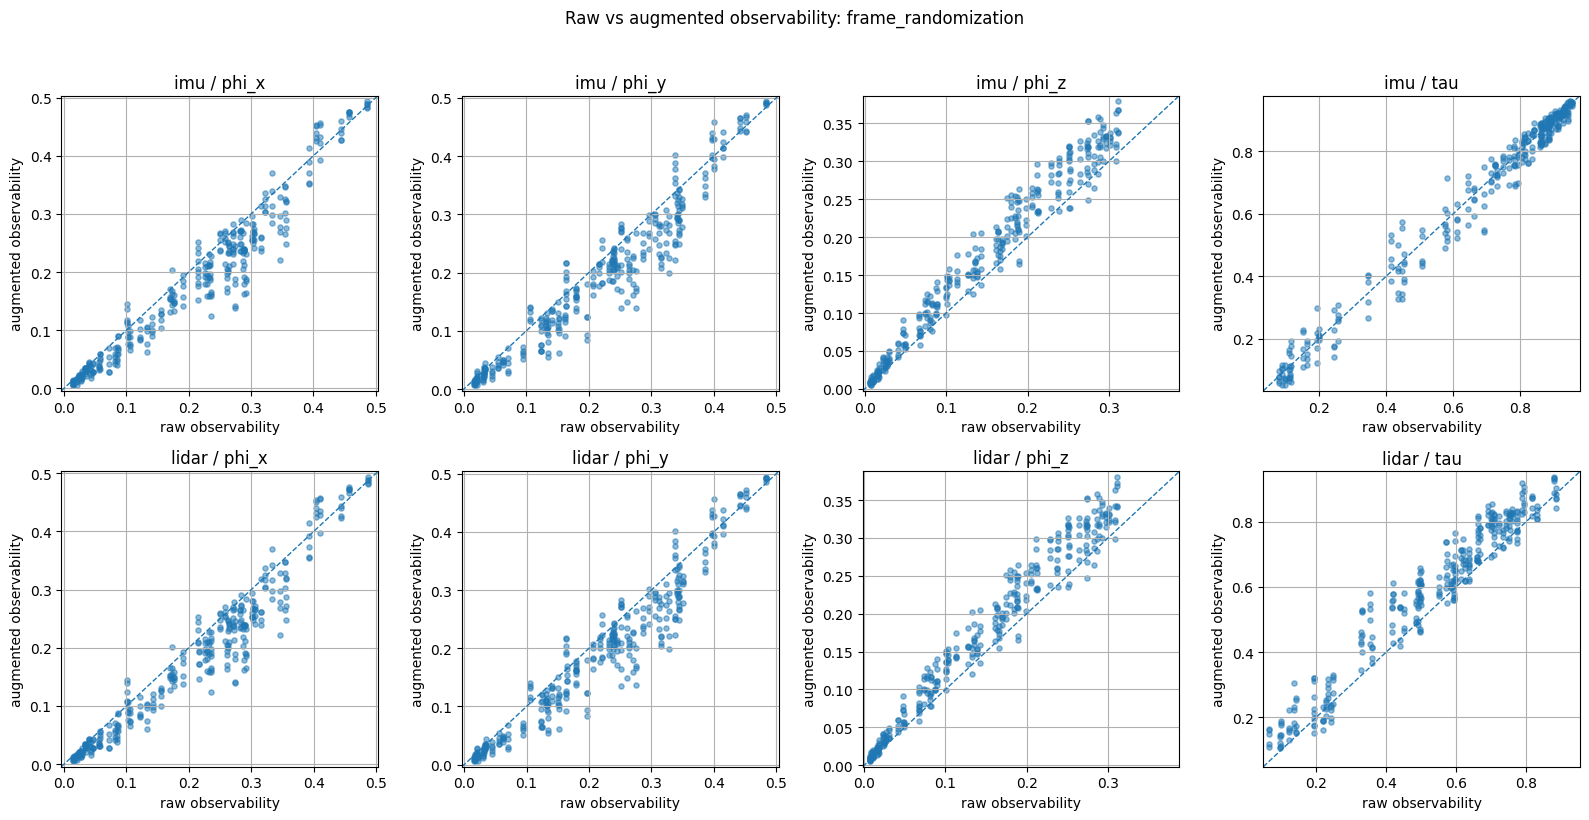

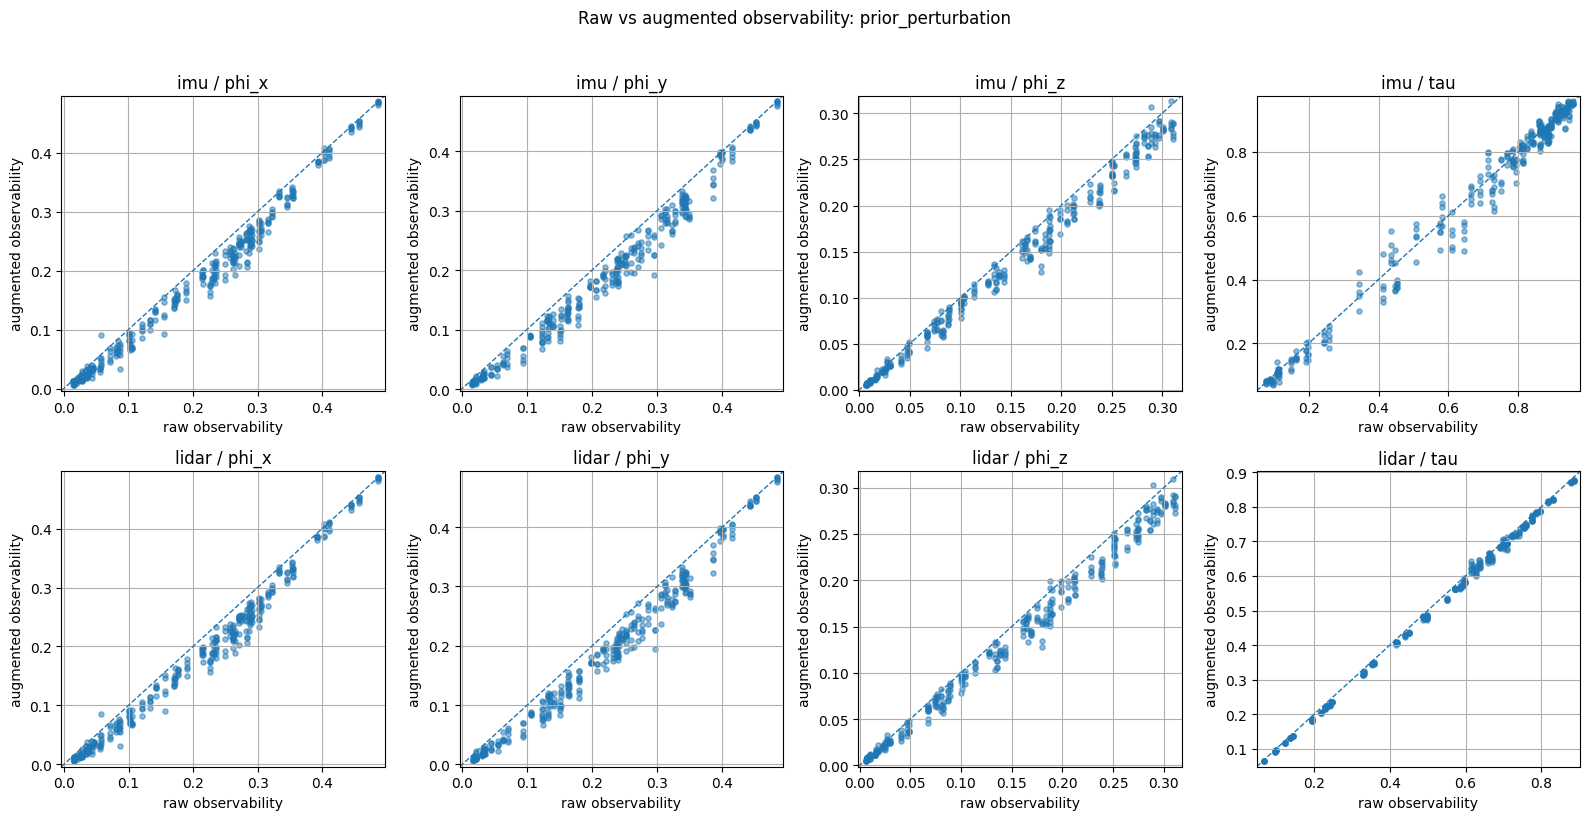

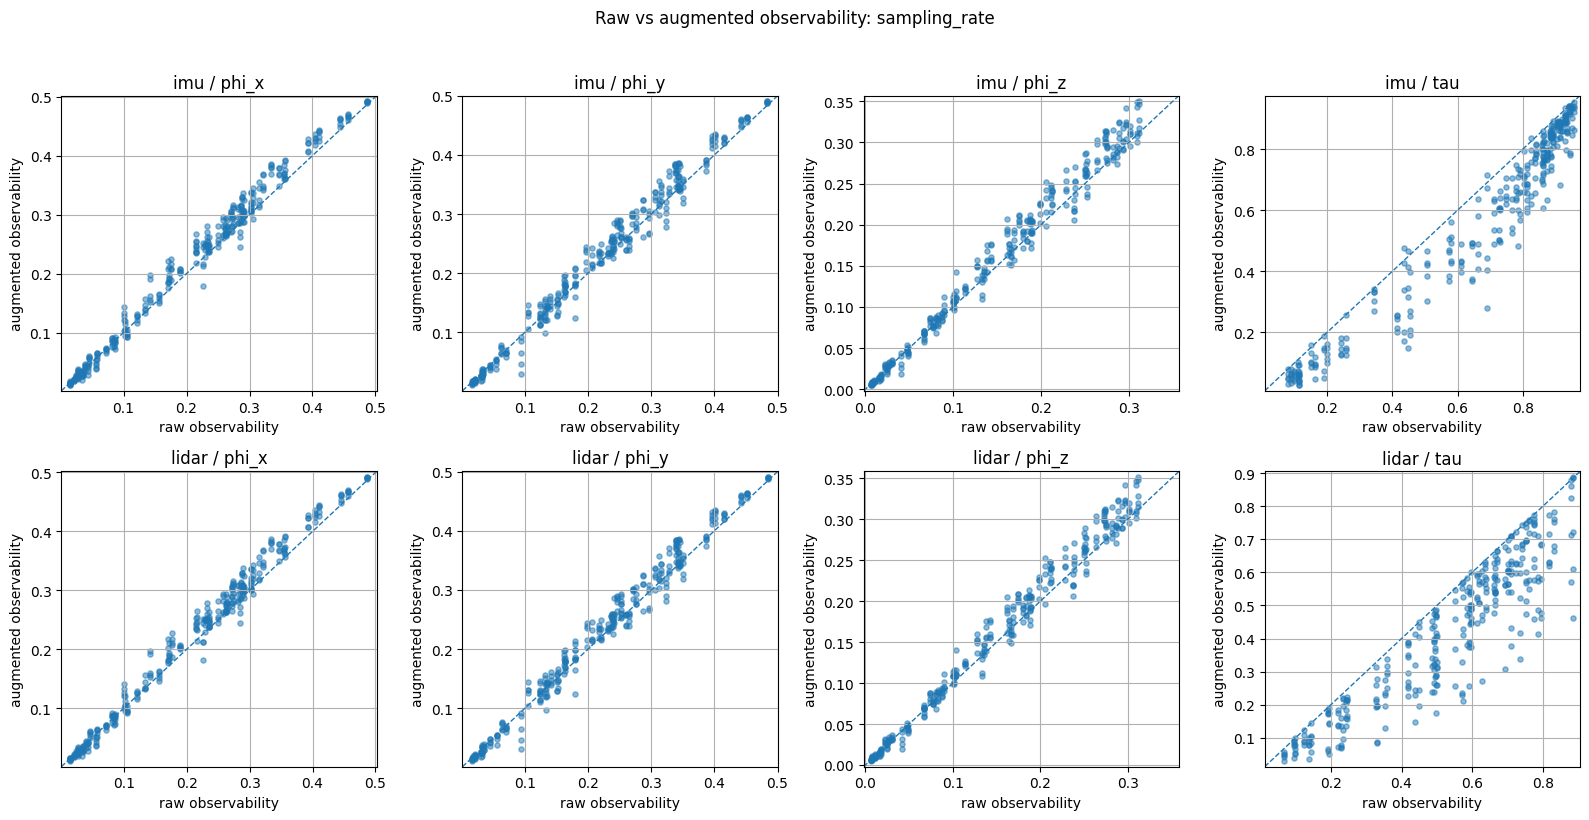

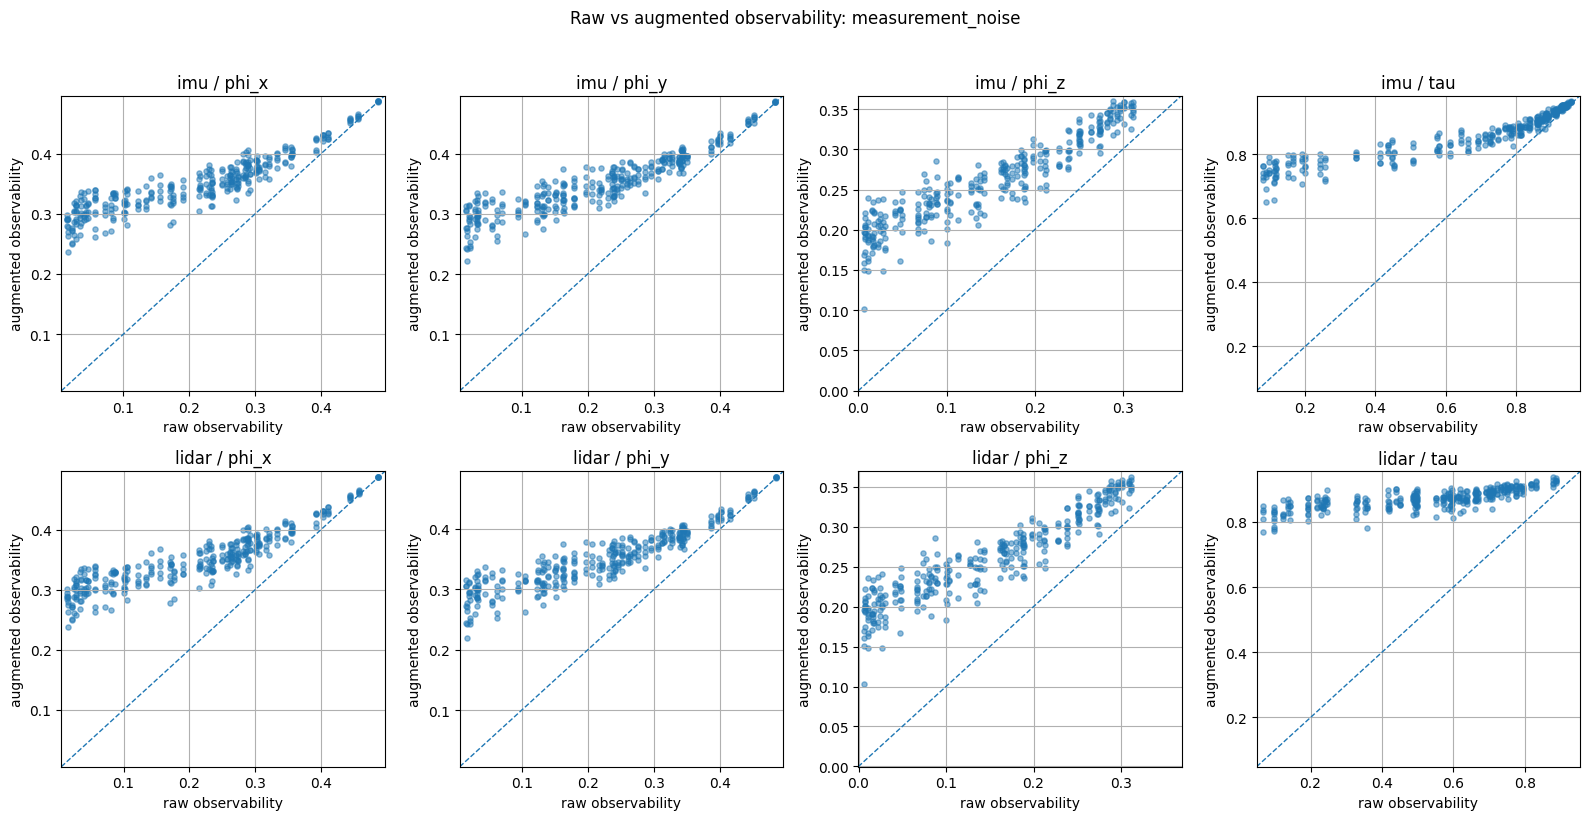

In [11]:
for augmentation_name in augmentation_pipelines:
    fig, axes = plt.subplots(
        len(CALIBRATION_KEYS),
        len(INFORMATIVE_COMPONENTS),
        figsize=(4.0 * len(INFORMATIVE_COMPONENTS), 4.0 * len(CALIBRATION_KEYS)),
        squeeze=False,
    )

    for calibration_index, calibration_key in enumerate(CALIBRATION_KEYS):
        for component_index, component_name in enumerate(INFORMATIVE_COMPONENTS):
            axis = axes[calibration_index, component_index]

            subset = augmentation_observability_pairs[
                (augmentation_observability_pairs["augmentation"] == augmentation_name)
                & (augmentation_observability_pairs["calibration"] == calibration_key)
                & (augmentation_observability_pairs["component"] == component_name)
            ]

            raw = subset["raw"].to_numpy()
            augmented = subset["augmented"].to_numpy()

            lower = min(float(np.min(raw)), float(np.min(augmented)))
            upper = max(float(np.max(raw)), float(np.max(augmented)))
            margin = max(0.02 * (upper - lower), 1e-4)

            axis.scatter(raw, augmented, s=14, alpha=0.5)
            axis.plot([lower - margin, upper + margin], [lower - margin, upper + margin], linestyle="--", linewidth=1.0)
            axis.set_xlim(lower - margin, upper + margin)
            axis.set_ylim(lower - margin, upper + margin)
            axis.set_xlabel("raw observability")
            axis.set_ylabel("augmented observability")
            axis.set_title(f"{calibration_key} / {component_name}")
            axis.grid(True)

    fig.suptitle(f"Raw vs augmented observability: {augmentation_name}", y=1.02)
    fig.tight_layout()
    plt.show()


## 11. Practical cached-label interpretation


In [12]:
def practical_drift_label(normalized_rmse):
    if not np.isfinite(normalized_rmse):
        return "degenerate target"
    if normalized_rmse < 0.02:
        return "tiny drift"
    if normalized_rmse < 0.10:
        return "moderate drift"
    return "recompute target"

decision_table = augmentation_drift_summary[
    augmentation_drift_summary["component"].isin(INFORMATIVE_COMPONENTS)
].copy()

decision_table["practical_label"] = decision_table["normalized_rmse"].map(practical_drift_label)

display(
    decision_table[
        [
            "augmentation",
            "calibration",
            "component",
            "pearson_r",
            "identity_r2",
            "normalized_rmse",
            "mae_drift",
            "max_abs_drift",
            "practical_label",
        ]
    ].sort_values(["augmentation", "calibration", "component"])
)


,augmentation,calibration,component,pearson_r,identity_r2,normalized_rmse,mae_drift,max_abs_drift,practical_label
0,frame_randomization,imu,phi_x,0.968455,0.900428,0.315550,0.029560,0.134660,recompute target
1,frame_randomization,imu,phi_y,0.962063,0.884630,0.339661,0.031550,0.136326,recompute target
2,frame_randomization,imu,phi_z,0.983793,0.877693,0.349725,0.027088,0.084715,recompute target
6,frame_randomization,imu,tau,0.990363,0.980182,0.140776,0.029720,0.147778,recompute target
7,frame_randomization,lidar,phi_x,0.968690,0.897974,0.319415,0.030189,0.134501,recompute target
8,frame_randomization,lidar,phi_y,0.961929,0.882835,0.342293,0.031816,0.138302,recompute target
9,frame_randomization,lidar,phi_z,0.983250,0.874996,0.353560,0.027506,0.086929,recompute target
13,frame_randomization,lidar,tau,0.971111,0.873043,0.356311,0.063953,0.228186,recompute target
14,measurement_noise,imu,phi_x,0.911454,-0.724622,1.313249,0.142299,0.300985,recompute target
15,measurement_noise,imu,phi_y,0.921742,-0.567957,1.252181,0.132426,0.302424,recompute target


## 12. Interpretation notes

The threshold labels above are practical heuristics rather than mathematical definitions.

A first-pass interpretation is:
- `normalized_rmse < 0.02`: very small drift relative to natural target variation;
- `0.02 <= normalized_rmse < 0.10`: inspect per-coordinate behavior before treating the augmentation as label-preserving;
- `normalized_rmse >= 0.10`: recompute the observability target after augmentation.

Frame randomization is special: under the current coordinate convention it is expected to be an invariance, so appreciable drift should trigger an implementation/semantics review even if the generic heuristic would otherwise call it acceptable.

Calibration events are intentionally omitted because a within-window calibration change no longer matches the current target semantics of one static 7D calibration per sensor.


# NN run

In [23]:
##################################################
# Load the best unaugmented observability predictor
##################################################

from torch.utils.data import DataLoader

from obscalib.config import ObservabilityPredictionHeadConfig, ObservabilityPredictionModelConfig, TransformerConfig
from obscalib.data.device import window_batch_to
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.observability_prediction_model import ObservabilityPredictionModel
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint


BEST_MODEL_RUN_NAME = "kaist_observability_predictor_008"
BEST_MODEL_CHECKPOINT = ROOT / "runs" / BEST_MODEL_RUN_NAME / "best.pt"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_DTYPE = torch.float32

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2

D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 8
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.1
NUM_SUMMARY_TOKENS = 1

HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.1
HEAD_MODE = "shared"


prediction_model_config = ObservabilityPredictionModelConfig(
    transformer=TransformerConfig(
        input_dim=TOKEN_INPUT_DIM,
        d_model=D_MODEL,
        n_heads=N_HEADS,
        num_layers=NUM_TRANSFORMER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=TRANSFORMER_DROPOUT,
        num_summary_tokens=NUM_SUMMARY_TOKENS,
        activation="gelu",
    ),
    calibration_keys=CALIBRATION_KEYS,
    head=ObservabilityPredictionHeadConfig(
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
    head_mode=HEAD_MODE,
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(
    measurement_dim=MEASUREMENT_DIM,
    calibration_keys=CALIBRATION_KEYS,
)


def build_prediction_model():
    return ObservabilityPredictionModel(prediction_model_config).to(
        device=DEVICE,
        dtype=MODEL_DTYPE,
    )


def forward_prediction_model(model, window):
    canonical_streams = geometry_processor(
        window.streams,
        window.metadata,
        window.current_calibration,
    )

    tokens = tokenizer(
        canonical_streams,
        observability=None,
    )

    if tokens.calibration_ids is None:
        raise ValueError(
            "Observability-prediction Tokenizer must emit calibration_ids."
        )

    return model(tokens)


prediction_model = build_prediction_model()

load_training_checkpoint(
    BEST_MODEL_CHECKPOINT,
    model=prediction_model,
    map_location=DEVICE,
    restore_rng_state=False,
)

print("Loaded:", BEST_MODEL_CHECKPOINT)
print(
    "Parameters:",
    sum(parameter.numel() for parameter in prediction_model.parameters()),
)

Loaded: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_observability_predictor_008/best.pt
Parameters: 1679367


In [24]:
##################################################
# Recalibrate BatchNorm on clean training windows
##################################################

BATCHNORM_BATCH_SIZE = 16

train_batchnorm_loader = DataLoader(
    train_dataset,
    batch_size=BATCHNORM_BATCH_SIZE,
    shuffle=False,
    drop_last=False,
    num_workers=0,
    collate_fn=collate_windows,
)


def recalibrate_prediction_batchnorm(model, loader):
    batchnorm_modules = [
        module
        for module in model.modules()
        if isinstance(
            module,
            torch.nn.modules.batchnorm._BatchNorm,
        )
    ]

    if not batchnorm_modules:
        print("No BatchNorm modules found.")
        model.eval()
        return

    original_momenta = {
        module: module.momentum
        for module in batchnorm_modules
    }

    model.eval()

    for module in batchnorm_modules:
        module.reset_running_stats()
        module.momentum = None
        module.train()

    with torch.no_grad():
        for base_window in tqdm(
            loader,
            desc="Recalibrating predictor BatchNorm",
        ):
            window = window_batch_to(
                base_window,
                DEVICE,
                dtype=MODEL_DTYPE,
            )

            forward_prediction_model(
                model,
                window,
            )

    for module in batchnorm_modules:
        module.momentum = original_momenta[module]
        module.eval()

    model.eval()


recalibrate_prediction_batchnorm(
    prediction_model,
    train_batchnorm_loader,
)

print("Predictor ready.")

Recalibrating predictor BatchNorm:   0%|          | 0/126 [00:00<?, ?it/s]

Predictor ready.


In [25]:
##################################################
# Compare raw and augmented NN predictions
##################################################

nn_ablation_records = []

augmented_target_lookup = (
    augmentation_observability_pairs
    .set_index(
        [
            "augmentation",
            "dataset_index",
            "draw",
            "calibration",
            "component",
        ]
    )["augmented"]
    .to_dict()
)

prediction_model.eval()

total_prediction_evaluations = (
    len(selected_dataset_indices)
    * (
        1
        + len(augmentation_pipelines)
        * NUM_AUGMENTATION_DRAWS
    )
)

progress = tqdm(
    total=total_prediction_evaluations,
    desc="NN augmentation sensitivity",
)

with torch.no_grad():
    for dataset_index in selected_dataset_indices:
        dataset_index = int(dataset_index)

        base_window = collate_windows(
            [
                train_dataset[
                    dataset_index
                ]
            ]
        )

        raw_target = raw_target_for_dataset_index(
            dataset_index
        ).to(
            device="cpu",
            dtype=torch.float32,
        )

        raw_device_window = window_batch_to(
            base_window,
            DEVICE,
            dtype=MODEL_DTYPE,
        )

        raw_output = forward_prediction_model(
            prediction_model,
            raw_device_window,
        )

        raw_prediction = torch.stack(
            [
                raw_output.predictions[
                    calibration_key
                ][0].detach().cpu()
                for calibration_key in CALIBRATION_KEYS
            ],
            dim=0,
        )

        progress.update(1)

        for augmentation_index, (
            augmentation_name,
            pipeline,
        ) in enumerate(
            augmentation_pipelines.items()
        ):
            for draw_index in range(
                NUM_AUGMENTATION_DRAWS
            ):
                seed = (
                    ABLATION_RANDOM_SEED
                    + 1_000_000 * augmentation_index
                    + 1000 * dataset_index
                    + draw_index
                )

                generator = torch.Generator().manual_seed(
                    seed
                )

                augmented_window = pipeline(
                    base_window,
                    generator=generator,
                ).augmented_window

                augmented_device_window = window_batch_to(
                    augmented_window,
                    DEVICE,
                    dtype=MODEL_DTYPE,
                )

                augmented_output = forward_prediction_model(
                    prediction_model,
                    augmented_device_window,
                )

                augmented_prediction = torch.stack(
                    [
                        augmented_output.predictions[
                            calibration_key
                        ][0].detach().cpu()
                        for calibration_key in CALIBRATION_KEYS
                    ],
                    dim=0,
                )

                for calibration_index, calibration_key in enumerate(
                    CALIBRATION_KEYS
                ):
                    for component_index, component_name in enumerate(
                        CALIBRATION_COMPONENT_NAMES
                    ):
                        augmented_target = float(
                            augmented_target_lookup[
                                (
                                    augmentation_name,
                                    dataset_index,
                                    draw_index,
                                    calibration_key,
                                    component_name,
                                )
                            ]
                        )

                        nn_ablation_records.append(
                            {
                                "augmentation": augmentation_name,
                                "dataset_index": dataset_index,
                                "draw": draw_index,
                                "calibration": calibration_key,
                                "component": component_name,
                                "raw_target": float(
                                    raw_target[
                                        calibration_index,
                                        component_index,
                                    ]
                                ),
                                "augmented_target": augmented_target,
                                "raw_prediction": float(
                                    raw_prediction[
                                        calibration_index,
                                        component_index,
                                    ]
                                ),
                                "augmented_prediction": float(
                                    augmented_prediction[
                                        calibration_index,
                                        component_index,
                                    ]
                                ),
                            }
                        )

                progress.update(1)

progress.close()

nn_augmentation_ablation = pd.DataFrame(
    nn_ablation_records
)

display(
    nn_augmentation_ablation.head()
)

NN augmentation sensitivity:   0%|          | 0/1344 [00:00<?, ?it/s]

,augmentation,dataset_index,draw,calibration,component,raw_target,augmented_target,raw_prediction,augmented_prediction
0,frame_randomization,1225,0,imu,phi_x,2.258028e-01,1.988299e-01,2.047334e-01,2.047339e-01
1,frame_randomization,1225,0,imu,phi_y,2.400500e-01,2.251116e-01,2.299100e-01,2.299110e-01
2,frame_randomization,1225,0,imu,phi_z,1.691317e-01,1.839616e-01,1.723097e-01,1.723102e-01
3,frame_randomization,1225,0,imu,rho_x,9.530990e-16,1.645789e-15,5.984734e-07,5.985356e-07
4,frame_randomization,1225,0,imu,rho_y,2.865542e-17,2.467965e-17,1.208699e-06,1.208823e-06


In [26]:
##################################################
# NN augmentation agreement metrics
##################################################

EPS = 1e-12


def agreement_metrics(reference, candidate):
    reference = np.asarray(
        reference,
        dtype=float,
    )

    candidate = np.asarray(
        candidate,
        dtype=float,
    )

    error = candidate - reference

    reference_mean = float(
        np.mean(
            reference
        )
    )

    reference_std = float(
        np.std(
            reference
        )
    )

    candidate_std = float(
        np.std(
            candidate
        )
    )

    mae = float(
        np.mean(
            np.abs(
                error
            )
        )
    )

    rmse = float(
        np.sqrt(
            np.mean(
                error**2
            )
        )
    )

    if (
        reference_std > EPS
        and candidate_std > EPS
    ):
        pearson_r = float(
            np.corrcoef(
                reference,
                candidate,
            )[0, 1]
        )
    else:
        pearson_r = np.nan

    denominator = float(
        np.sum(
            (
                reference
                - reference_mean
            ) ** 2
        )
    )

    if denominator > EPS:
        r2 = (
            1.0
            - float(
                np.sum(
                    error**2
                )
            )
            / denominator
        )

        normalized_rmse = (
            rmse
            / reference_std
        )

    else:
        r2 = np.nan
        normalized_rmse = np.nan

    return {
        "pearson": pearson_r,
        "r2": r2,
        "mae": mae,
        "rmse": rmse,
        "normalized_rmse": normalized_rmse,
    }


nn_summary_rows = []

for (
    augmentation_name,
    calibration_key,
    component_name,
), group in nn_augmentation_ablation.groupby(
    [
        "augmentation",
        "calibration",
        "component",
    ]
):
    raw_target = group[
        "raw_target"
    ].to_numpy()

    augmented_target = group[
        "augmented_target"
    ].to_numpy()

    raw_prediction = group[
        "raw_prediction"
    ].to_numpy()

    augmented_prediction = group[
        "augmented_prediction"
    ].to_numpy()

    raw_prediction_metrics = agreement_metrics(
        raw_target,
        raw_prediction,
    )

    augmented_prediction_to_raw_metrics = agreement_metrics(
        raw_target,
        augmented_prediction,
    )

    augmented_prediction_to_augmented_metrics = agreement_metrics(
        augmented_target,
        augmented_prediction,
    )

    augmented_fisher_to_raw_metrics = agreement_metrics(
        raw_target,
        augmented_target,
    )

    prediction_invariance_metrics = agreement_metrics(
        raw_prediction,
        augmented_prediction,
    )

    nn_summary_rows.append(
        {
            "augmentation": augmentation_name,
            "calibration": calibration_key,
            "component": component_name,

            "raw_pred_R2": raw_prediction_metrics["r2"],

            "aug_pred_vs_raw_R2": augmented_prediction_to_raw_metrics["r2"],
            "aug_pred_vs_raw_Pearson": augmented_prediction_to_raw_metrics["pearson"],
            "aug_pred_vs_raw_MAE": augmented_prediction_to_raw_metrics["mae"],

            "aug_pred_vs_aug_R2": augmented_prediction_to_augmented_metrics["r2"],

            "aug_fisher_vs_raw_R2": augmented_fisher_to_raw_metrics["r2"],

            "prediction_invariance_R2": prediction_invariance_metrics["r2"],
            "prediction_invariance_NRMSE": prediction_invariance_metrics["normalized_rmse"],
        }
    )

nn_augmentation_summary = pd.DataFrame(
    nn_summary_rows
)

display(
    nn_augmentation_summary[
        nn_augmentation_summary[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ].style.format({
        "raw_pred_R2": "{:.4f}",
        "aug_pred_vs_raw_R2": "{:.4f}",
        "aug_pred_vs_raw_Pearson": "{:.4f}",
        "aug_pred_vs_raw_MAE": "{:.4f}",
        "aug_pred_vs_aug_R2": "{:.4f}",
        "aug_fisher_vs_raw_R2": "{:.4f}",
        "prediction_invariance_R2": "{:.4f}",
        "prediction_invariance_NRMSE": "{:.4f}",
    })
)

,augmentation,calibration,component,raw_pred_R2,aug_pred_vs_raw_R2,aug_pred_vs_raw_Pearson,aug_pred_vs_raw_MAE,aug_pred_vs_aug_R2,aug_fisher_vs_raw_R2,prediction_invariance_R2,prediction_invariance_NRMSE
0,frame_randomization,imu,phi_x,0.9330,0.9330,0.9703,0.0229,0.8619,0.9004,1.0000,0.0000
1,frame_randomization,imu,phi_y,0.8239,0.8239,0.9196,0.0378,0.8293,0.8846,1.0000,0.0000
2,frame_randomization,imu,phi_z,0.8830,0.8830,0.9449,0.0239,0.7603,0.8777,1.0000,0.0000
6,frame_randomization,imu,tau,0.9390,0.9390,0.9773,0.0539,0.9353,0.9802,1.0000,0.0000
7,frame_randomization,lidar,phi_x,0.9332,0.9332,0.9732,0.0239,0.8838,0.8980,1.0000,0.0000
8,frame_randomization,lidar,phi_y,0.8320,0.8320,0.9250,0.0375,0.8376,0.8828,1.0000,0.0000
9,frame_randomization,lidar,phi_z,0.8809,0.8809,0.9485,0.0251,0.7376,0.8750,1.0000,0.0000
13,frame_randomization,lidar,tau,0.7662,0.7662,0.9197,0.0821,0.5446,0.8730,1.0000,0.0000
14,measurement_noise,imu,phi_x,0.9330,0.7850,0.9577,0.0454,-5.2852,-0.7246,0.7376,0.5122
15,measurement_noise,imu,phi_y,0.8239,0.7099,0.9106,0.0557,-4.1342,-0.5680,0.6604,0.5827


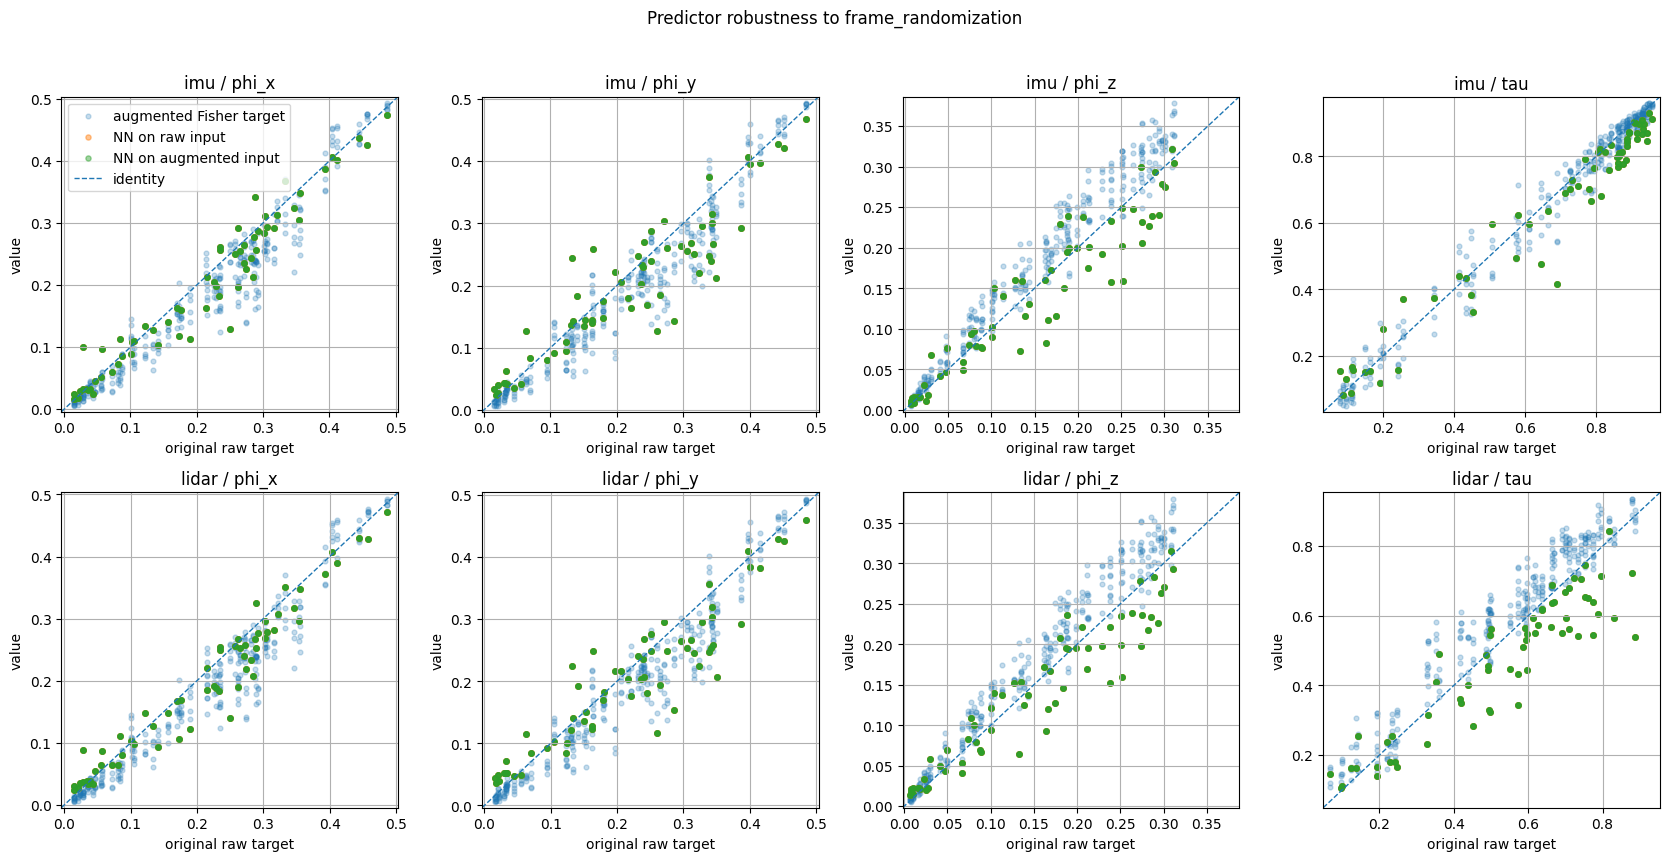

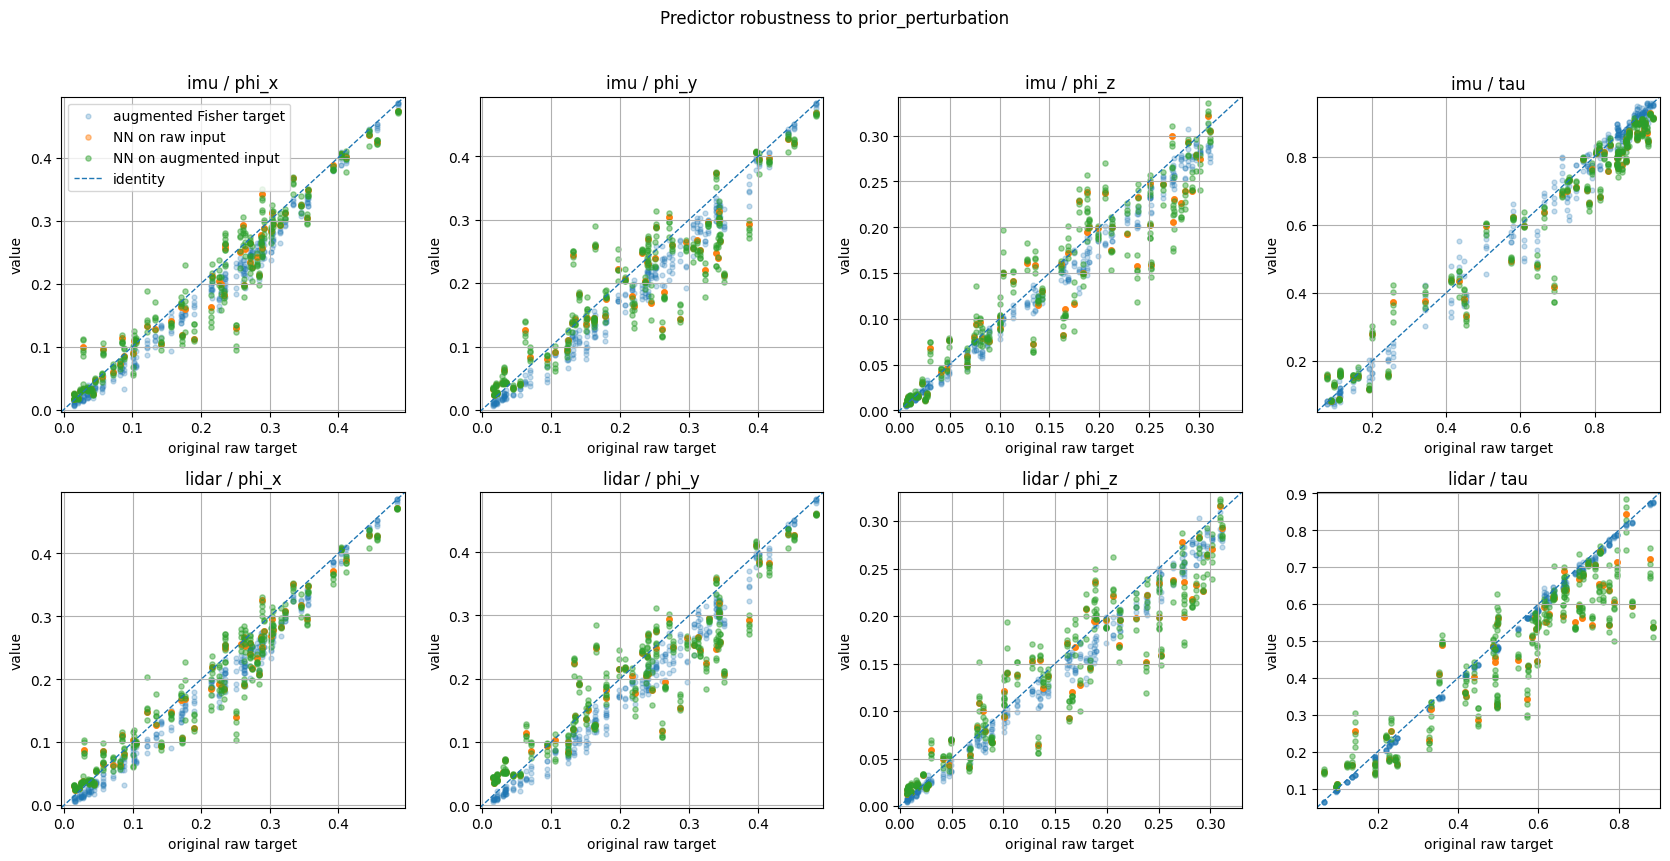

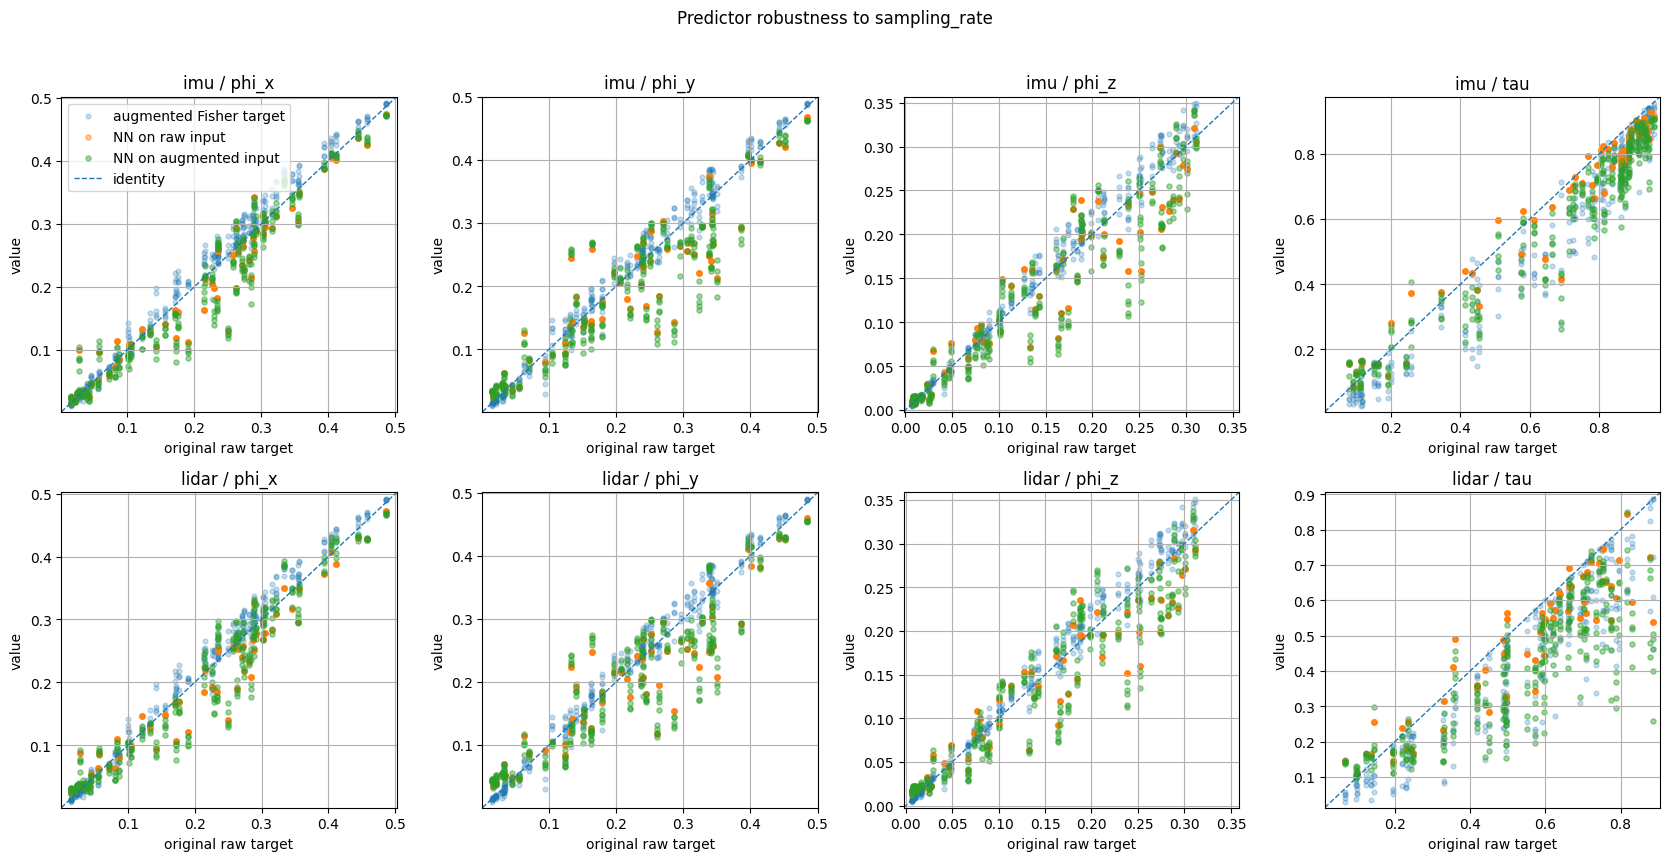

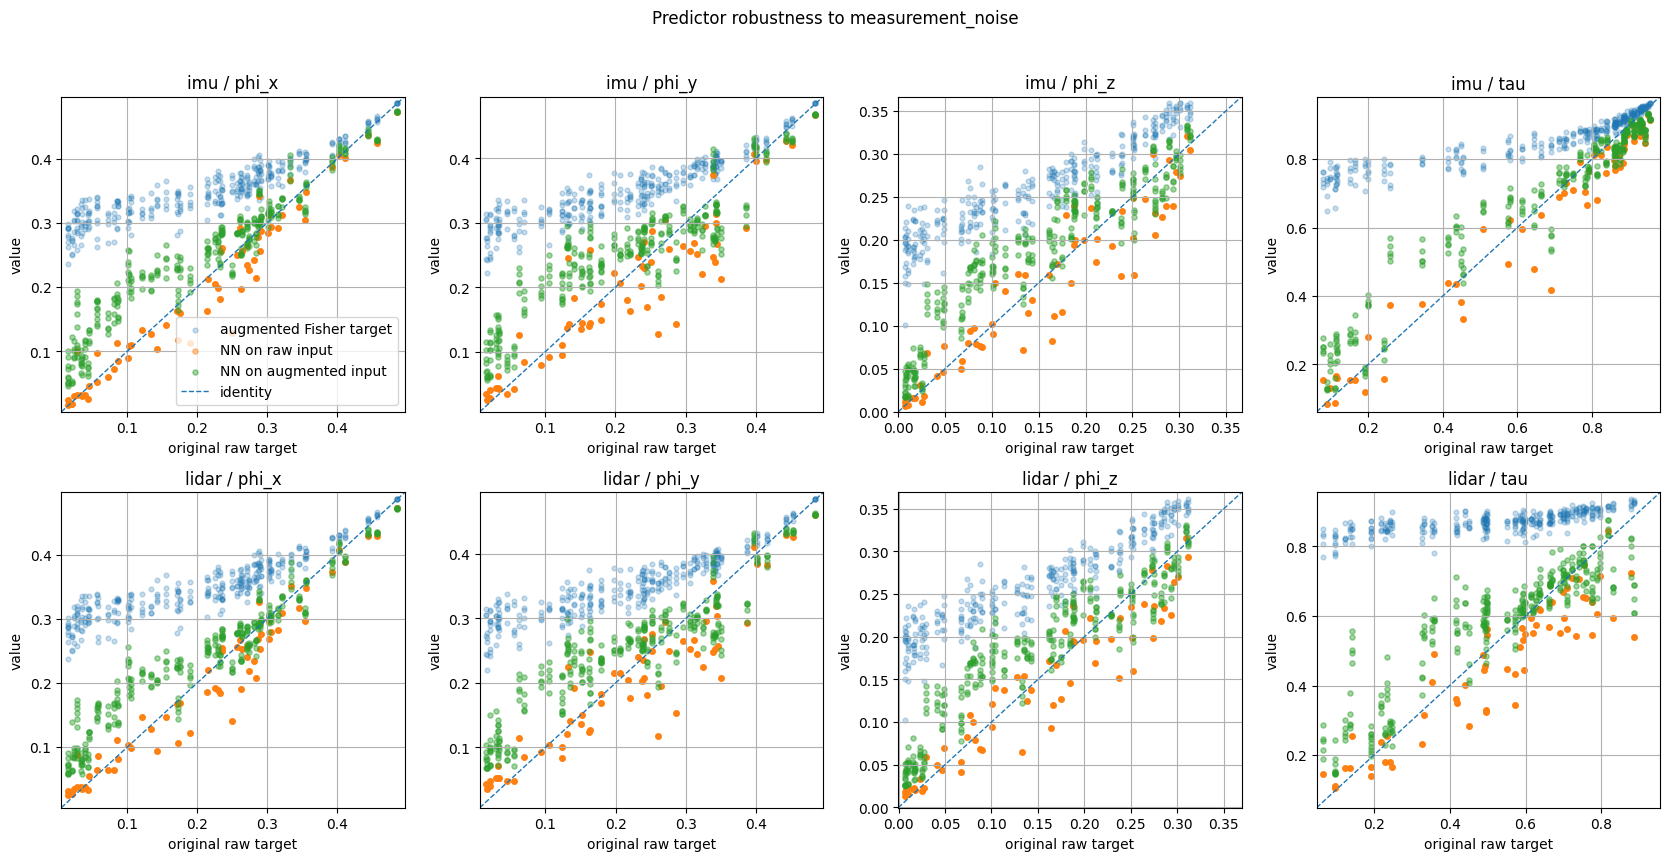

In [27]:
##################################################
# Raw target vs Fisher target vs NN predictions
##################################################

for augmentation_name in augmentation_pipelines:
    fig, axes = plt.subplots(
        len(CALIBRATION_KEYS),
        len(INFORMATIVE_COMPONENTS),
        figsize=(
            4.2 * len(INFORMATIVE_COMPONENTS),
            4.2 * len(CALIBRATION_KEYS),
        ),
        squeeze=False,
    )

    for calibration_index, calibration_key in enumerate(
        CALIBRATION_KEYS
    ):
        for component_index, component_name in enumerate(
            INFORMATIVE_COMPONENTS
        ):
            axis = axes[
                calibration_index,
                component_index,
            ]

            subset = nn_augmentation_ablation[
                (nn_augmentation_ablation["augmentation"] == augmentation_name)
                & (nn_augmentation_ablation["calibration"] == calibration_key)
                & (nn_augmentation_ablation["component"] == component_name)
            ]

            raw_target = subset[
                "raw_target"
            ].to_numpy()

            augmented_target = subset[
                "augmented_target"
            ].to_numpy()

            raw_prediction = subset[
                "raw_prediction"
            ].to_numpy()

            augmented_prediction = subset[
                "augmented_prediction"
            ].to_numpy()

            all_values = np.concatenate(
                [
                    raw_target,
                    augmented_target,
                    raw_prediction,
                    augmented_prediction,
                ]
            )

            lower = float(
                np.min(
                    all_values
                )
            )

            upper = float(
                np.max(
                    all_values
                )
            )

            margin = max(
                0.02 * (
                    upper
                    - lower
                ),
                1e-4,
            )

            axis.scatter(
                raw_target,
                augmented_target,
                s=12,
                alpha=0.25,
                label="augmented Fisher target",
            )

            axis.scatter(
                raw_target,
                raw_prediction,
                s=14,
                alpha=0.45,
                label="NN on raw input",
            )

            axis.scatter(
                raw_target,
                augmented_prediction,
                s=14,
                alpha=0.45,
                label="NN on augmented input",
            )

            axis.plot(
                [
                    lower - margin,
                    upper + margin,
                ],
                [
                    lower - margin,
                    upper + margin,
                ],
                linestyle="--",
                linewidth=1.0,
                label="identity",
            )

            axis.set_xlim(
                lower - margin,
                upper + margin,
            )

            axis.set_ylim(
                lower - margin,
                upper + margin,
            )

            axis.set_xlabel(
                "original raw target"
            )

            axis.set_ylabel(
                "value"
            )

            axis.set_title(
                f"{calibration_key} / {component_name}"
            )

            axis.grid(
                True
            )

            if (
                calibration_index == 0
                and component_index == 0
            ):
                axis.legend()

    fig.suptitle(
        f"Predictor robustness to {augmentation_name}",
        y=1.02,
    )

    fig.tight_layout()

    plt.show()

In [28]:
##################################################
# Augmentation-response diagnostics
##################################################

EPS = 1e-12


def regression_metrics(reference, prediction):
    reference = np.asarray(reference, dtype=float)
    prediction = np.asarray(prediction, dtype=float)

    error = prediction - reference

    reference_mean = float(np.mean(reference))
    reference_std = float(np.std(reference))
    prediction_std = float(np.std(prediction))

    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error**2)))

    if reference_std > EPS and prediction_std > EPS:
        pearson_r = float(np.corrcoef(reference, prediction)[0, 1])
    else:
        pearson_r = np.nan

    denominator = float(np.sum((reference - reference_mean) ** 2))

    if denominator > EPS:
        r2 = 1.0 - float(np.sum(error**2)) / denominator
        normalized_rmse = rmse / reference_std
    else:
        r2 = np.nan
        normalized_rmse = np.nan

    return {
        "pearson_r": pearson_r,
        "r2": r2,
        "mae": mae,
        "rmse": rmse,
        "normalized_rmse": normalized_rmse,
    }


augmentation_response_rows = []

for (
    augmentation_name,
    calibration_key,
    component_name,
), group in nn_augmentation_ablation.groupby(
    [
        "augmentation",
        "calibration",
        "component",
    ]
):
    raw_target = group["raw_target"].to_numpy(dtype=float)
    augmented_target = group["augmented_target"].to_numpy(dtype=float)

    raw_prediction = group["raw_prediction"].to_numpy(dtype=float)
    augmented_prediction = group["augmented_prediction"].to_numpy(dtype=float)

    ##################################################
    # Absolute prediction quality
    ##################################################

    raw_metrics = regression_metrics(
        raw_target,
        raw_prediction,
    )

    augmented_vs_raw_metrics = regression_metrics(
        raw_target,
        augmented_prediction,
    )

    augmented_vs_augmented_metrics = regression_metrics(
        augmented_target,
        augmented_prediction,
    )

    ##################################################
    # Augmentation response
    #
    # This directly measures whether the NN learned:
    #
    #     o_aug - o_raw
    #
    # rather than merely predicting reasonable absolute values.
    ##################################################

    target_delta = augmented_target - raw_target
    prediction_delta = augmented_prediction - raw_prediction

    delta_metrics = regression_metrics(
        target_delta,
        prediction_delta,
    )

    ##################################################
    # Direction of augmentation response
    ##################################################

    nonzero_target_delta = np.abs(target_delta) > 1e-8

    if np.any(nonzero_target_delta):
        sign_accuracy = float(
            np.mean(
                np.sign(
                    prediction_delta[
                        nonzero_target_delta
                    ]
                )
                ==
                np.sign(
                    target_delta[
                        nonzero_target_delta
                    ]
                )
            )
        )
    else:
        sign_accuracy = np.nan

    augmentation_response_rows.append(
        {
            "augmentation": augmentation_name,
            "calibration": calibration_key,
            "component": component_name,

            "raw_pred_R2": raw_metrics["r2"],

            # Useful for nuisance augmentations such as measurement noise.
            "aug_pred_vs_raw_R2": augmented_vs_raw_metrics["r2"],

            # Primary absolute metric for target-changing augmentations.
            "aug_pred_vs_aug_R2": augmented_vs_augmented_metrics["r2"],
            "aug_pred_vs_aug_Pearson": augmented_vs_augmented_metrics["pearson_r"],
            "aug_pred_vs_aug_MAE": augmented_vs_augmented_metrics["mae"],

            # Primary diagnostic of whether the model learned the augmentation effect.
            "delta_R2": delta_metrics["r2"],
            "delta_Pearson": delta_metrics["pearson_r"],
            "delta_MAE": delta_metrics["mae"],
            "delta_RMSE": delta_metrics["rmse"],
            "delta_NRMSE": delta_metrics["normalized_rmse"],
            "delta_sign_accuracy": sign_accuracy,

            "target_delta_std": float(np.std(target_delta)),
            "prediction_delta_std": float(np.std(prediction_delta)),
        }
    )


augmentation_response_summary = pd.DataFrame(
    augmentation_response_rows
)

display(
    augmentation_response_summary[
        augmentation_response_summary[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ].style.format({
        "raw_pred_R2": "{:.4f}",
        "aug_pred_vs_raw_R2": "{:.4f}",
        "aug_pred_vs_aug_R2": "{:.4f}",
        "aug_pred_vs_aug_Pearson": "{:.4f}",
        "aug_pred_vs_aug_MAE": "{:.4f}",
        "delta_R2": "{:.4f}",
        "delta_Pearson": "{:.4f}",
        "delta_MAE": "{:.4f}",
        "delta_RMSE": "{:.4f}",
        "delta_NRMSE": "{:.4f}",
        "delta_sign_accuracy": "{:.3f}",
        "target_delta_std": "{:.4f}",
        "prediction_delta_std": "{:.4f}",
    })
)

,augmentation,calibration,component,raw_pred_R2,aug_pred_vs_raw_R2,aug_pred_vs_aug_R2,aug_pred_vs_aug_Pearson,aug_pred_vs_aug_MAE,delta_R2,delta_Pearson,delta_MAE,delta_RMSE,delta_NRMSE,delta_sign_accuracy,target_delta_std,prediction_delta_std
0,frame_randomization,imu,phi_x,0.9330,0.9330,0.8619,0.9346,0.0343,-0.5865,0.2427,0.0296,0.0399,1.2596,0.438,0.0317,0.0000
1,frame_randomization,imu,phi_y,0.8239,0.8239,0.8293,0.9126,0.0387,-0.5113,0.2223,0.0316,0.0422,1.2294,0.500,0.0343,0.0000
2,frame_randomization,imu,phi_z,0.8830,0.8830,0.7603,0.9371,0.0393,-1.3885,-0.2465,0.0271,0.0339,1.5455,0.491,0.0220,0.0000
6,frame_randomization,imu,tau,0.9390,0.9390,0.9353,0.9733,0.0572,-0.0198,-0.0271,0.0297,0.0404,1.0099,0.416,0.0400,0.0000
7,frame_randomization,lidar,phi_x,0.9332,0.9332,0.8838,0.9443,0.0329,-0.6327,0.2351,0.0302,0.0404,1.2778,0.425,0.0316,0.0000
8,frame_randomization,lidar,phi_y,0.8320,0.8320,0.8376,0.9192,0.0389,-0.5297,0.1981,0.0318,0.0425,1.2368,0.481,0.0344,0.0000
9,frame_randomization,lidar,phi_z,0.8809,0.8809,0.7376,0.9389,0.0414,-1.4219,-0.2290,0.0275,0.0343,1.5562,0.503,0.0220,0.0000
13,frame_randomization,lidar,tau,0.7662,0.7662,0.5446,0.9085,0.1258,-1.1455,-0.0259,0.0640,0.0792,1.4648,0.500,0.0540,0.0000
14,measurement_noise,imu,phi_x,0.9330,0.7850,-5.2852,0.8881,0.1019,-0.7327,0.6678,0.0902,0.1125,1.3163,0.981,0.0855,0.0347
15,measurement_noise,imu,phi_y,0.8239,0.7099,-4.1342,0.8601,0.0965,-0.6352,0.5422,0.0803,0.1042,1.2788,0.988,0.0815,0.0347


In [29]:
##################################################
# Compact augmentation-response summary
##################################################

informative_response_summary = (
    augmentation_response_summary[
        augmentation_response_summary[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ]
    .groupby(
        "augmentation"
    )
    .agg(
        mean_raw_R2=(
            "raw_pred_R2",
            "mean",
        ),
        mean_aug_vs_raw_R2=(
            "aug_pred_vs_raw_R2",
            "mean",
        ),
        mean_aug_vs_aug_R2=(
            "aug_pred_vs_aug_R2",
            "mean",
        ),
        worst_aug_vs_aug_R2=(
            "aug_pred_vs_aug_R2",
            "min",
        ),
        mean_delta_R2=(
            "delta_R2",
            "mean",
        ),
        worst_delta_R2=(
            "delta_R2",
            "min",
        ),
        mean_delta_Pearson=(
            "delta_Pearson",
            "mean",
        ),
        mean_delta_NRMSE=(
            "delta_NRMSE",
            "mean",
        ),
        mean_delta_sign_accuracy=(
            "delta_sign_accuracy",
            "mean",
        ),
    )
    .reset_index()
)

display(
    informative_response_summary.style.format({
        "mean_raw_R2": "{:.4f}",
        "mean_aug_vs_raw_R2": "{:.4f}",
        "mean_aug_vs_aug_R2": "{:.4f}",
        "worst_aug_vs_aug_R2": "{:.4f}",
        "mean_delta_R2": "{:.4f}",
        "worst_delta_R2": "{:.4f}",
        "mean_delta_Pearson": "{:.4f}",
        "mean_delta_NRMSE": "{:.4f}",
        "mean_delta_sign_accuracy": "{:.3f}",
    })
)

,augmentation,mean_raw_R2,mean_aug_vs_raw_R2,mean_aug_vs_aug_R2,worst_aug_vs_aug_R2,mean_delta_R2,worst_delta_R2,mean_delta_Pearson,mean_delta_NRMSE,mean_delta_sign_accuracy
0,frame_randomization,0.8739,0.8739,0.7988,0.5446,-0.7795,-1.4219,0.0462,1.3225,0.469
1,measurement_noise,0.8739,0.7748,-19.5017,-121.7324,-0.9918,-1.7769,0.4745,1.3993,0.988
2,prior_perturbation,0.8739,0.8611,0.8696,0.7802,-3.9995,-15.2400,-0.0325,2.0941,0.509
3,sampling_rate,0.8739,0.7954,0.8502,0.7823,-0.4303,-1.2691,0.4297,1.1754,0.656


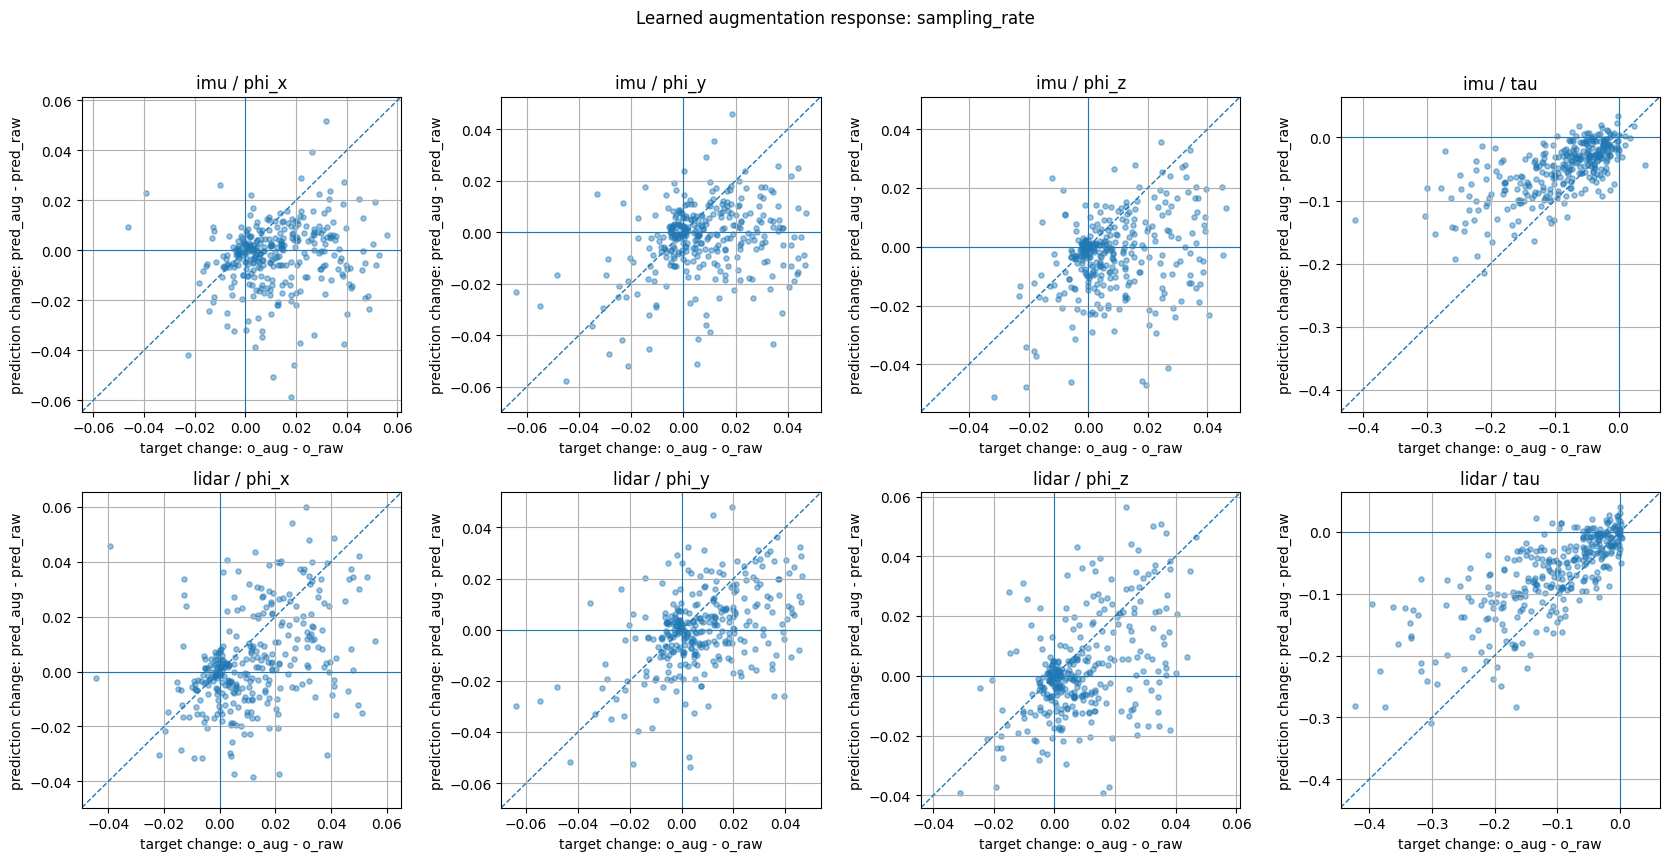

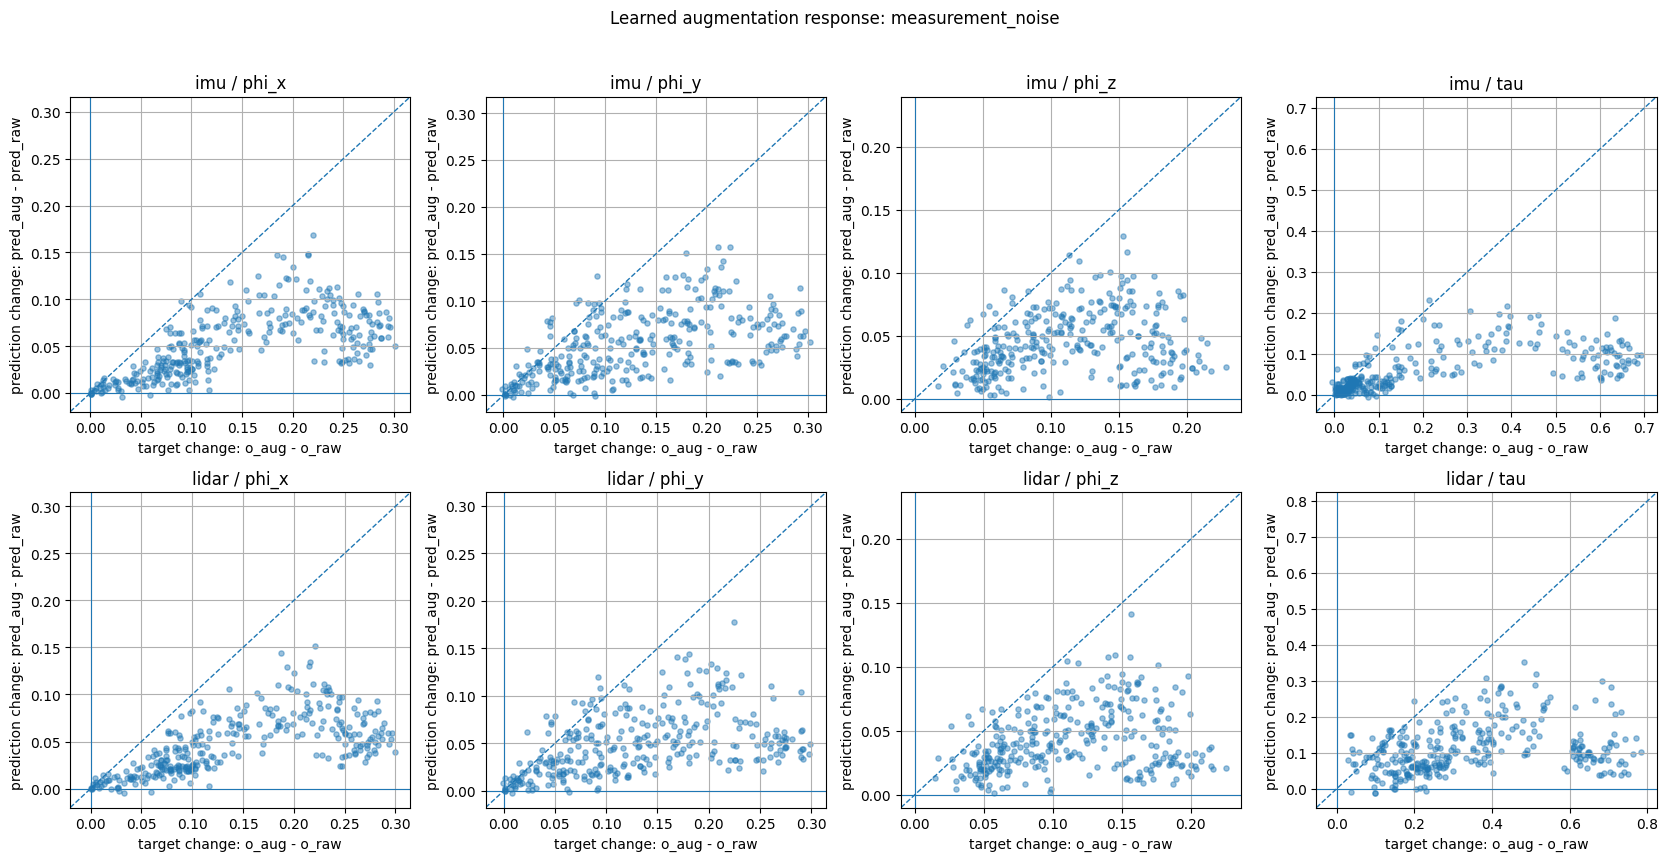

In [30]:
##################################################
# Target augmentation response vs NN augmentation response
##################################################

for augmentation_name in (
    "sampling_rate",
    "measurement_noise",
):
    fig, axes = plt.subplots(
        len(CALIBRATION_KEYS),
        len(INFORMATIVE_COMPONENTS),
        figsize=(
            4.2 * len(INFORMATIVE_COMPONENTS),
            4.2 * len(CALIBRATION_KEYS),
        ),
        squeeze=False,
    )

    for calibration_index, calibration_key in enumerate(
        CALIBRATION_KEYS
    ):
        for component_index, component_name in enumerate(
            INFORMATIVE_COMPONENTS
        ):
            axis = axes[
                calibration_index,
                component_index,
            ]

            subset = nn_augmentation_ablation[
                (nn_augmentation_ablation["augmentation"] == augmentation_name)
                & (nn_augmentation_ablation["calibration"] == calibration_key)
                & (nn_augmentation_ablation["component"] == component_name)
            ]

            target_delta = (
                subset["augmented_target"].to_numpy()
                - subset["raw_target"].to_numpy()
            )

            prediction_delta = (
                subset["augmented_prediction"].to_numpy()
                - subset["raw_prediction"].to_numpy()
            )

            all_values = np.concatenate(
                [
                    target_delta,
                    prediction_delta,
                ]
            )

            lower = float(
                np.min(
                    all_values
                )
            )

            upper = float(
                np.max(
                    all_values
                )
            )

            margin = max(
                0.05 * (
                    upper
                    - lower
                ),
                1e-4,
            )

            axis.scatter(
                target_delta,
                prediction_delta,
                s=14,
                alpha=0.45,
            )

            axis.plot(
                [
                    lower - margin,
                    upper + margin,
                ],
                [
                    lower - margin,
                    upper + margin,
                ],
                linestyle="--",
                linewidth=1.0,
                label="perfect response",
            )

            axis.axhline(
                0.0,
                linewidth=0.8,
            )

            axis.axvline(
                0.0,
                linewidth=0.8,
            )

            axis.set_xlim(
                lower - margin,
                upper + margin,
            )

            axis.set_ylim(
                lower - margin,
                upper + margin,
            )

            axis.set_xlabel(
                "target change: o_aug - o_raw"
            )

            axis.set_ylabel(
                "prediction change: pred_aug - pred_raw"
            )

            axis.set_title(
                f"{calibration_key} / {component_name}"
            )

            axis.grid(
                True
            )

    fig.suptitle(
        f"Learned augmentation response: {augmentation_name}",
        y=1.02,
    )

    fig.tight_layout()

    plt.show()

In [31]:
##################################################
# Compare multiple predictor checkpoints
##################################################

CHECKPOINT_RUN_NAMES = (
    "kaist_observability_predictor_007",
    "kaist_observability_predictor_008",
)


def evaluate_predictor_checkpoint(run_name):
    checkpoint_path = (
        ROOT
        / "runs"
        / run_name
        / "best.pt"
    )

    evaluation_model = build_prediction_model()

    load_training_checkpoint(
        checkpoint_path,
        model=evaluation_model,
        map_location=DEVICE,
        restore_rng_state=False,
    )

    recalibrate_prediction_batchnorm(
        evaluation_model,
        train_batchnorm_loader,
    )

    evaluation_model.eval()

    records = []

    total = (
        len(selected_dataset_indices)
        * (
            1
            + len(augmentation_pipelines)
            * NUM_AUGMENTATION_DRAWS
        )
    )

    progress = tqdm(
        total=total,
        desc=f"Evaluating {run_name}",
    )

    with torch.no_grad():
        for dataset_index in selected_dataset_indices:
            dataset_index = int(
                dataset_index
            )

            base_window = collate_windows(
                [
                    train_dataset[
                        dataset_index
                    ]
                ]
            )

            raw_target = raw_target_for_dataset_index(
                dataset_index
            ).to(
                device="cpu",
                dtype=torch.float32,
            )

            raw_device_window = window_batch_to(
                base_window,
                DEVICE,
                dtype=MODEL_DTYPE,
            )

            raw_output = forward_prediction_model(
                evaluation_model,
                raw_device_window,
            )

            raw_prediction = torch.stack(
                [
                    raw_output.predictions[
                        calibration_key
                    ][0].detach().cpu()
                    for calibration_key in CALIBRATION_KEYS
                ],
                dim=0,
            )

            progress.update(
                1
            )

            for augmentation_index, (
                augmentation_name,
                pipeline,
            ) in enumerate(
                augmentation_pipelines.items()
            ):
                for draw_index in range(
                    NUM_AUGMENTATION_DRAWS
                ):
                    seed = (
                        ABLATION_RANDOM_SEED
                        + 1_000_000
                        * augmentation_index
                        + 1000
                        * dataset_index
                        + draw_index
                    )

                    generator = torch.Generator().manual_seed(
                        seed
                    )

                    augmented_window = pipeline(
                        base_window,
                        generator=generator,
                    ).augmented_window

                    augmented_device_window = window_batch_to(
                        augmented_window,
                        DEVICE,
                        dtype=MODEL_DTYPE,
                    )

                    augmented_output = forward_prediction_model(
                        evaluation_model,
                        augmented_device_window,
                    )

                    augmented_prediction = torch.stack(
                        [
                            augmented_output.predictions[
                                calibration_key
                            ][0].detach().cpu()
                            for calibration_key in CALIBRATION_KEYS
                        ],
                        dim=0,
                    )

                    for calibration_index, calibration_key in enumerate(
                        CALIBRATION_KEYS
                    ):
                        for component_index, component_name in enumerate(
                            CALIBRATION_COMPONENT_NAMES
                        ):
                            augmented_target = float(
                                augmented_target_lookup[
                                    (
                                        augmentation_name,
                                        dataset_index,
                                        draw_index,
                                        calibration_key,
                                        component_name,
                                    )
                                ]
                            )

                            records.append(
                                {
                                    "run": run_name,
                                    "augmentation": augmentation_name,
                                    "dataset_index": dataset_index,
                                    "draw": draw_index,
                                    "calibration": calibration_key,
                                    "component": component_name,
                                    "raw_target": float(
                                        raw_target[
                                            calibration_index,
                                            component_index,
                                        ]
                                    ),
                                    "augmented_target": augmented_target,
                                    "raw_prediction": float(
                                        raw_prediction[
                                            calibration_index,
                                            component_index,
                                        ]
                                    ),
                                    "augmented_prediction": float(
                                        augmented_prediction[
                                            calibration_index,
                                            component_index,
                                        ]
                                    ),
                                }
                            )

                    progress.update(
                        1
                    )

    progress.close()

    return pd.DataFrame(
        records
    )


checkpoint_ablation_results = pd.concat(
    [
        evaluate_predictor_checkpoint(
            run_name
        )
        for run_name in CHECKPOINT_RUN_NAMES
    ],
    ignore_index=True,
)

print(
    "Rows:",
    len(
        checkpoint_ablation_results
    ),
)

Recalibrating predictor BatchNorm:   0%|          | 0/126 [00:00<?, ?it/s]

Evaluating kaist_observability_predictor_007:   0%|          | 0/1344 [00:00<?, ?it/s]

Recalibrating predictor BatchNorm:   0%|          | 0/126 [00:00<?, ?it/s]

Evaluating kaist_observability_predictor_008:   0%|          | 0/1344 [00:00<?, ?it/s]

Rows: 35840


In [32]:
##################################################
# 007 vs 008 augmentation-response comparison
##################################################

checkpoint_summary_rows = []

for (
    run_name,
    augmentation_name,
    calibration_key,
    component_name,
), group in checkpoint_ablation_results.groupby(
    [
        "run",
        "augmentation",
        "calibration",
        "component",
    ]
):
    raw_target = group["raw_target"].to_numpy(dtype=float)
    augmented_target = group["augmented_target"].to_numpy(dtype=float)

    raw_prediction = group["raw_prediction"].to_numpy(dtype=float)
    augmented_prediction = group["augmented_prediction"].to_numpy(dtype=float)

    augmented_metrics = regression_metrics(
        augmented_target,
        augmented_prediction,
    )

    target_delta = (
        augmented_target
        - raw_target
    )

    prediction_delta = (
        augmented_prediction
        - raw_prediction
    )

    delta_metrics = regression_metrics(
        target_delta,
        prediction_delta,
    )

    raw_target_metrics = regression_metrics(
        raw_target,
        augmented_prediction,
    )

    checkpoint_summary_rows.append(
        {
            "run": run_name,
            "augmentation": augmentation_name,
            "calibration": calibration_key,
            "component": component_name,

            "aug_pred_vs_aug_R2": augmented_metrics["r2"],
            "aug_pred_vs_aug_Pearson": augmented_metrics["pearson_r"],

            "aug_pred_vs_raw_R2": raw_target_metrics["r2"],

            "delta_R2": delta_metrics["r2"],
            "delta_Pearson": delta_metrics["pearson_r"],
            "delta_NRMSE": delta_metrics["normalized_rmse"],
        }
    )


checkpoint_response_summary = pd.DataFrame(
    checkpoint_summary_rows
)

display(
    checkpoint_response_summary[
        checkpoint_response_summary[
            "component"
        ].isin(
            INFORMATIVE_COMPONENTS
        )
    ].sort_values(
        [
            "augmentation",
            "calibration",
            "component",
            "run",
        ]
    ).style.format({
        "aug_pred_vs_aug_R2": "{:.4f}",
        "aug_pred_vs_aug_Pearson": "{:.4f}",
        "aug_pred_vs_raw_R2": "{:.4f}",
        "delta_R2": "{:.4f}",
        "delta_Pearson": "{:.4f}",
        "delta_NRMSE": "{:.4f}",
    })
)

,run,augmentation,calibration,component,aug_pred_vs_aug_R2,aug_pred_vs_aug_Pearson,aug_pred_vs_raw_R2,delta_R2,delta_Pearson,delta_NRMSE
0,kaist_observability_predictor_007,frame_randomization,imu,phi_x,0.8316,0.9306,0.9324,-0.5865,0.2800,1.2596
56,kaist_observability_predictor_008,frame_randomization,imu,phi_x,0.8619,0.9346,0.9330,-0.5865,0.2427,1.2596
1,kaist_observability_predictor_007,frame_randomization,imu,phi_y,0.7329,0.8735,0.7855,-0.5113,0.1834,1.2294
57,kaist_observability_predictor_008,frame_randomization,imu,phi_y,0.8293,0.9126,0.8239,-0.5113,0.2223,1.2294
2,kaist_observability_predictor_007,frame_randomization,imu,phi_z,0.7630,0.9165,0.8343,-1.3885,-0.2082,1.5455
58,kaist_observability_predictor_008,frame_randomization,imu,phi_z,0.7603,0.9371,0.8830,-1.3885,-0.2465,1.5455
6,kaist_observability_predictor_007,frame_randomization,imu,tau,0.9371,0.9690,0.9457,-0.0198,-0.0507,1.0099
62,kaist_observability_predictor_008,frame_randomization,imu,tau,0.9353,0.9733,0.9390,-0.0198,-0.0271,1.0099
7,kaist_observability_predictor_007,frame_randomization,lidar,phi_x,0.8421,0.9328,0.9292,-0.6327,0.1812,1.2778
63,kaist_observability_predictor_008,frame_randomization,lidar,phi_x,0.8838,0.9443,0.9332,-0.6327,0.2351,1.2778


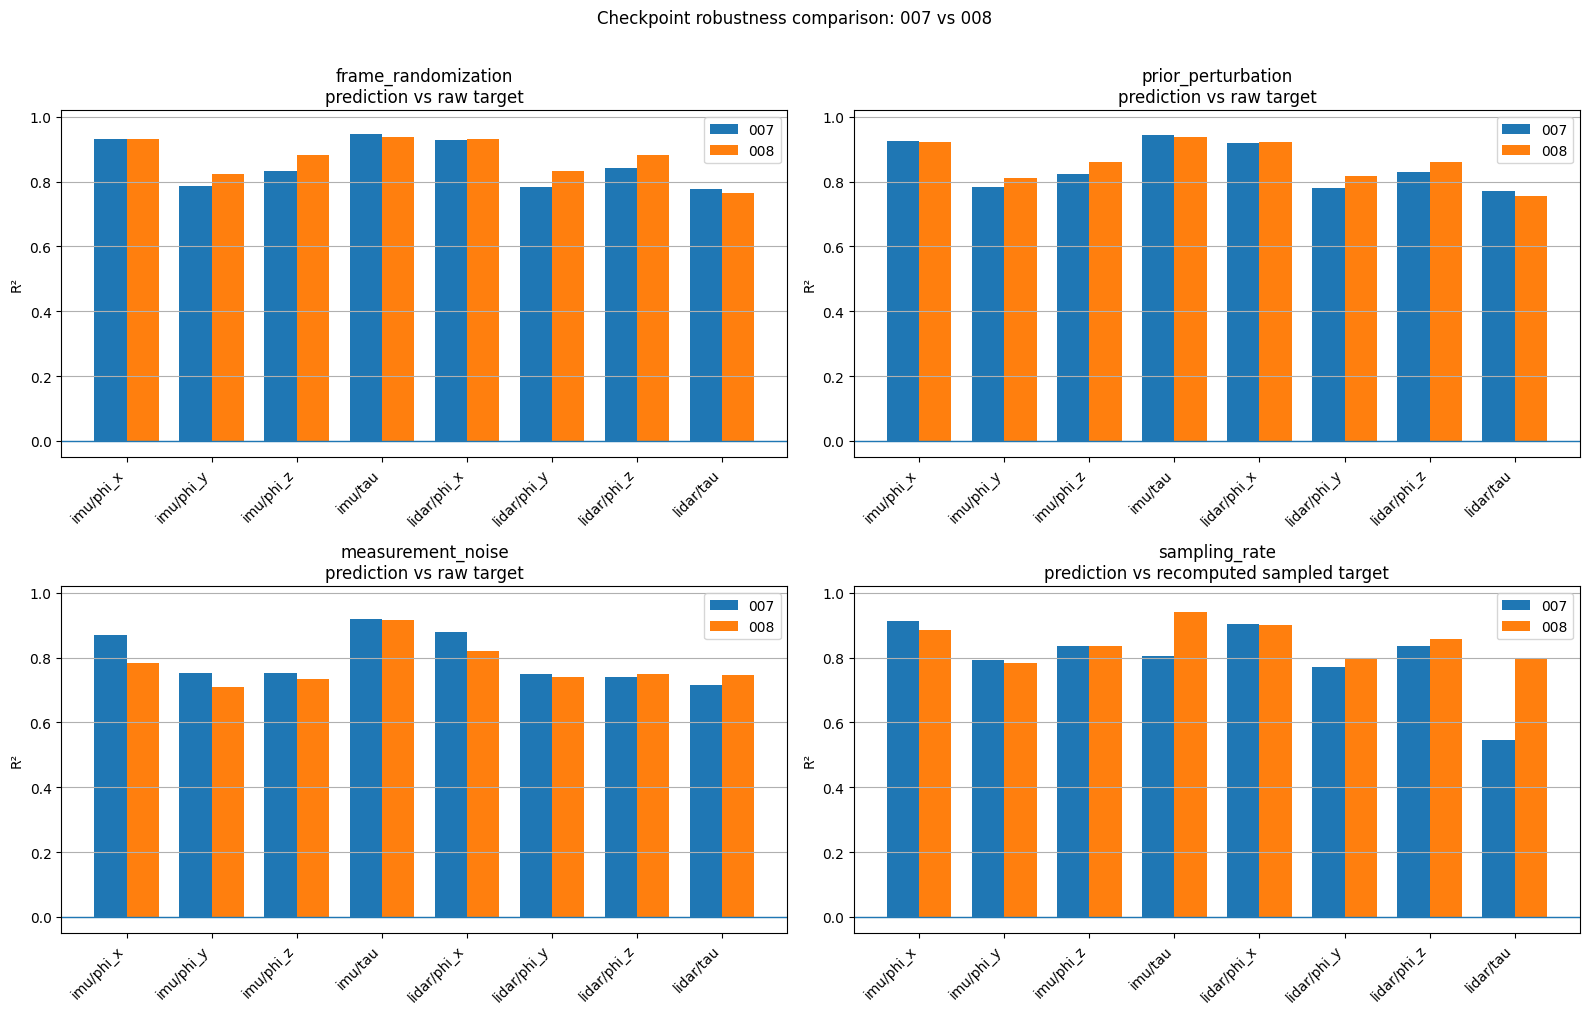

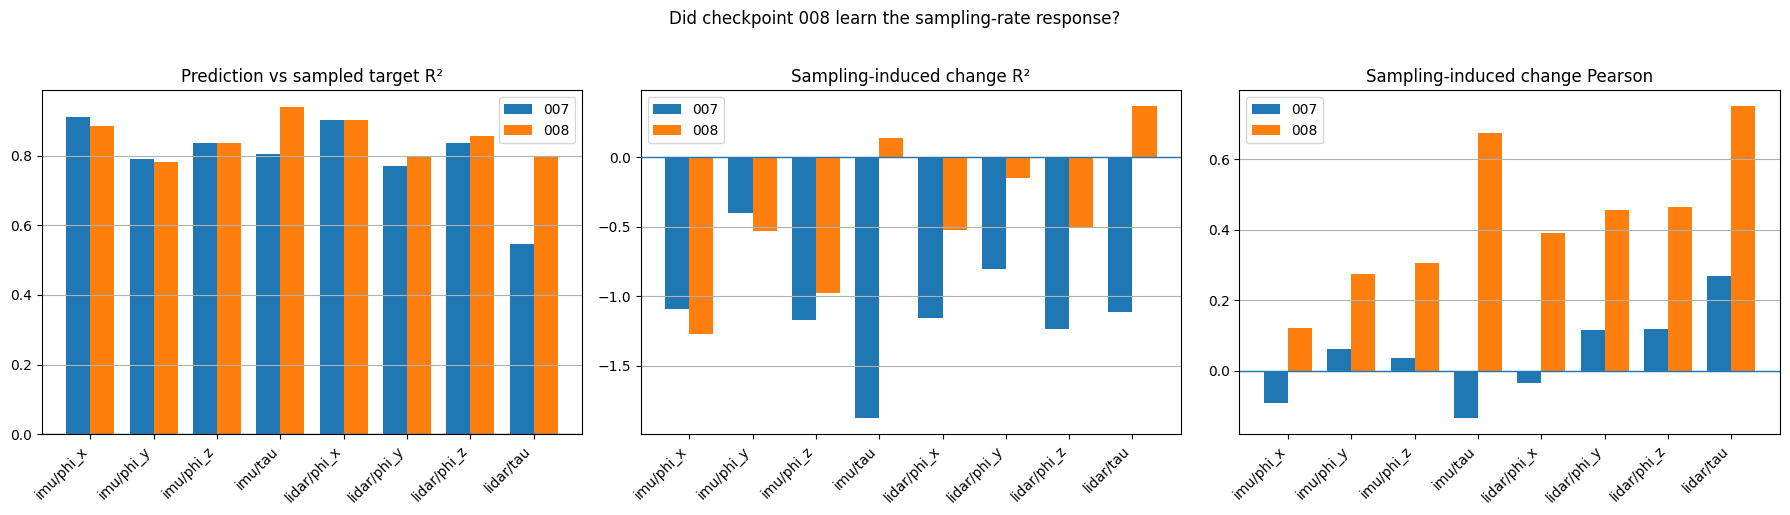

In [33]:
##################################################
# Visualize checkpoint 007 vs 008 augmentation performance
##################################################

RUN_ORDER = (
    "kaist_observability_predictor_007",
    "kaist_observability_predictor_008",
)

RUN_LABELS = {
    "kaist_observability_predictor_007": "007",
    "kaist_observability_predictor_008": "008",
}

COORDINATE_ORDER = [
    f"{calibration}/{component}"
    for calibration in CALIBRATION_KEYS
    for component in INFORMATIVE_COMPONENTS
]

AUGMENTATION_ORDER = (
    "frame_randomization",
    "prior_perturbation",
    "measurement_noise",
    "sampling_rate",
)

# The scientifically relevant absolute-target metric differs by augmentation.
PRIMARY_METRIC_BY_AUGMENTATION = {
    "frame_randomization": "aug_pred_vs_raw_R2",
    "prior_perturbation": "aug_pred_vs_raw_R2",
    "measurement_noise": "aug_pred_vs_raw_R2",
    "sampling_rate": "aug_pred_vs_aug_R2",
}

PRIMARY_TARGET_LABEL_BY_AUGMENTATION = {
    "frame_randomization": "raw target",
    "prior_perturbation": "raw target",
    "measurement_noise": "raw target",
    "sampling_rate": "recomputed sampled target",
}


##################################################
# Figure 1: semantically correct R² for every augmentation
##################################################

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 10),
    sharey=False,
)

axes = axes.reshape(-1)

for axis, augmentation_name in zip(axes, AUGMENTATION_ORDER):
    metric_name = PRIMARY_METRIC_BY_AUGMENTATION[
        augmentation_name
    ]

    subset = checkpoint_response_summary[
        (checkpoint_response_summary["augmentation"] == augmentation_name)
        & checkpoint_response_summary["component"].isin(INFORMATIVE_COMPONENTS)
    ].copy()

    subset["coordinate"] = (
        subset["calibration"]
        + "/"
        + subset["component"]
    )

    pivot = (
        subset
        .pivot(
            index="coordinate",
            columns="run",
            values=metric_name,
        )
        .reindex(
            COORDINATE_ORDER
        )
    )

    x = np.arange(
        len(
            COORDINATE_ORDER
        )
    )

    width = 0.38

    for run_index, run_name in enumerate(
        RUN_ORDER
    ):
        offset = (
            run_index
            - (
                len(
                    RUN_ORDER
                )
                - 1
            )
            / 2
        ) * width

        axis.bar(
            x + offset,
            pivot[
                run_name
            ].to_numpy(),
            width=width,
            label=RUN_LABELS[
                run_name
            ],
        )

    finite_values = pivot.to_numpy().ravel()
    finite_values = finite_values[
        np.isfinite(
            finite_values
        )
    ]

    lower_limit = min(
        -0.05,
        float(
            finite_values.min()
        )
        - 0.05,
    )

    axis.axhline(
        0.0,
        linewidth=1.0,
    )

    axis.set_ylim(
        lower_limit,
        1.02,
    )

    axis.set_xticks(
        x
    )

    axis.set_xticklabels(
        COORDINATE_ORDER,
        rotation=45,
        ha="right",
    )

    axis.set_ylabel(
        "R²"
    )

    axis.set_title(
        f"{augmentation_name}\n"
        f"prediction vs {PRIMARY_TARGET_LABEL_BY_AUGMENTATION[augmentation_name]}"
    )

    axis.grid(
        True,
        axis="y",
    )

    axis.legend()

fig.suptitle(
    "Checkpoint robustness comparison: 007 vs 008",
    y=1.01,
)

fig.tight_layout()

plt.show()


##################################################
# Figure 2: sampling-rate response specifically
##################################################

sampling_subset = checkpoint_response_summary[
    (checkpoint_response_summary["augmentation"] == "sampling_rate")
    & checkpoint_response_summary["component"].isin(INFORMATIVE_COMPONENTS)
].copy()

sampling_subset["coordinate"] = (
    sampling_subset["calibration"]
    + "/"
    + sampling_subset["component"]
)

SAMPLING_RESPONSE_METRICS = (
    (
        "aug_pred_vs_aug_R2",
        "Prediction vs sampled target R²",
    ),
    (
        "delta_R2",
        "Sampling-induced change R²",
    ),
    (
        "delta_Pearson",
        "Sampling-induced change Pearson",
    ),
)

fig, axes = plt.subplots(
    1,
    len(
        SAMPLING_RESPONSE_METRICS
    ),
    figsize=(18, 5),
)

x = np.arange(
    len(
        COORDINATE_ORDER
    )
)

width = 0.38

for axis, (
    metric_name,
    title,
) in zip(
    axes,
    SAMPLING_RESPONSE_METRICS,
):
    pivot = (
        sampling_subset
        .pivot(
            index="coordinate",
            columns="run",
            values=metric_name,
        )
        .reindex(
            COORDINATE_ORDER
        )
    )

    for run_index, run_name in enumerate(
        RUN_ORDER
    ):
        offset = (
            run_index
            - (
                len(
                    RUN_ORDER
                )
                - 1
            )
            / 2
        ) * width

        axis.bar(
            x + offset,
            pivot[
                run_name
            ].to_numpy(),
            width=width,
            label=RUN_LABELS[
                run_name
            ],
        )

    axis.axhline(
        0.0,
        linewidth=1.0,
    )

    axis.set_xticks(
        x
    )

    axis.set_xticklabels(
        COORDINATE_ORDER,
        rotation=45,
        ha="right",
    )

    axis.set_title(
        title
    )

    axis.grid(
        True,
        axis="y",
    )

    axis.legend()

fig.suptitle(
    "Did checkpoint 008 learn the sampling-rate response?",
    y=1.02,
)

fig.tight_layout()

plt.show()